# LINEAR REGRESSION 
# Bùi Đức Phát-235700-DH23TIN06

## 1. Tổng quan nghiên cứu

Nghiên cứu tập trung khảo sát khả năng ứng dụng các phương pháp hồi quy trong phân tích và dự đoán giá bộ nhớ RAM dựa trên ba bộ dữ liệu có cấu trúc và đặc điểm khác nhau. Mục tiêu chính là xây dựng mô hình dự đoán, đánh giá hiệu suất trên từng bộ dữ liệu và phân tích những yếu tố ảnh hưởng đến kết quả thực nghiệm.

Ba bộ dữ liệu được sử dụng bao gồm:

1. **Dataset 1 – CostInflation DDR5 RAM:** Dữ liệu giá bán lẻ RAM DDR5 được chuẩn hóa theo dung lượng, biểu diễn bằng USD/GB và ghi nhận theo thời gian.
2. **Dataset 2 – eBay Listings:** Dữ liệu tin niêm yết RAM trên nền tảng thương mại điện tử, bao gồm các thuộc tính sản phẩm và giá niêm yết tính bằng USD.
3. **Dataset 3 – TechFuelHQ:** Dữ liệu theo dõi giá RAM theo thời gian kết hợp với một số đặc trưng kỹ thuật của sản phẩm, trong đó biến mục tiêu là giá trên mỗi GB (USD/GB).

## 2. Phương pháp nghiên cứu

Phương pháp chính được khảo sát là **Linear Regression**, kết hợp với các kỹ thuật tiền xử lý và cải thiện mô hình, bao gồm:

- Ordinary Least Squares (OLS): Mô hình hồi quy tuyến tính cơ sở.
- Log-transformation: Biến đổi biến mục tiêu bằng hàm logarit nhằm xem xét ảnh hưởng của phân phối giá lệch.
- Ridge Regression: Phương pháp hồi quy tuyến tính có điều chuẩn L2 nhằm kiểm soát độ lớn của hệ số và hạn chế overfitting.
- Polynomial Regression: Mở rộng tập đặc trưng bằng các thành phần đa thức để mô hình hóa một số quan hệ phi tuyến trong dữ liệu.
- Feature Engineering: Xây dựng các đặc trưng bổ sung từ thông tin thời gian và thuộc tính sản phẩm.
- StandardScaler và One-Hot Encoding: Chuẩn hóa biến số và mã hóa biến phân loại.



## 3. Nội dung thực nghiệm

Quá trình thực nghiệm được triển khai theo các nội dung chính:

1. Phân tích khám phá dữ liệu (EDA), đánh giá cấu trúc, phân phối và chất lượng dữ liệu.
2. Tiền xử lý dữ liệu, xử lý giá trị thiếu, bản ghi trùng lặp và các quan sát bất thường.
3. Xây dựng mô hình Linear Regression trên từng bộ dữ liệu.
4. Khảo sát các phương pháp cải tiến như Ridge Regression, biến đổi logarit và kỹ nghệ đặc trưng.
5. Đánh giá mô hình thông qua MAE, RMSE và hệ số xác định R².
6. So sánh kết quả giữa các phương pháp và phân tích những hạn chế của thực nghiệm.

Nghiên cứu hướng đến việc đánh giá khả năng ứng dụng hồi quy trong bài toán dự đoán giá RAM. Các kết quả ngoại suy trong tương lai chỉ được xem xét trong phạm vi dữ liệu và giả định của mô hình, không được xem là dự báo chắc chắn về diễn biến thị trường.

In [15]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, TimeSeriesSplit
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)
DATA_DIR = Path("data")
FILE_1 = DATA_DIR / "costinflation-ddr5-ram-retail-prices-raw-2026-07-13-to-2026-08-10.csv"
FILE_2 = DATA_DIR / "ram_pricing_intelligence_2026.csv"
FILE_3 = DATA_DIR / "ram-price-observations.csv"

for p in [FILE_1, FILE_2, FILE_3]:
    print(p, "FOUND" if p.exists() else "NOT FOUND")
if not all(p.exists() for p in [FILE_1, FILE_2, FILE_3]):
    raise FileNotFoundError("Đặt đủ 3 file CSV vào thư mục data cạnh notebook.")

df1 = pd.read_csv(FILE_1, dtype={"geography_id": "string"})
df2 = pd.read_csv(FILE_2)
df3 = pd.read_csv(FILE_3)

for name, df in [("D1 CostInflation", df1), ("D2 Kaggle (eBay)", df2), ("D3 TechFuelHQ", df3)]:
    print(f"{name}: shape={df.shape}")
    display(df.head(3))


data\costinflation-ddr5-ram-retail-prices-raw-2026-07-13-to-2026-08-10.csv FOUND
data\ram_pricing_intelligence_2026.csv FOUND
data\ram-price-observations.csv FOUND
D1 CostInflation: shape=(19705, 16)


,series_id,series_title,canonical_url,geography_type,geography_id,geography_label,observed_date,product_name,quantity_value,quantity_unit,quantity_name,price_amount,currency_code,normalized_price_amount,normalized_quantity_value,normalized_quantity_unit
0,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,A-Tech 16GB DDR5 5600MHz PC5-44800 CL46 SODIMM...,16,gigabytes,16 gigabytes,230.93,USD,14.4331,1,gigabytes
1,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,Acer Predator Vesta II RGB DDR5 RAM 32GB (16GB...,32,gigabytes,32 gigabytes,437.99,USD,13.6872,1,gigabytes
2,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,Biwin Black Opal DW100 DDR5 RGB RAM 48GB (24GB...,48,gigabytes,48 gigabytes,529.99,USD,11.0415,1,gigabytes


D2 Kaggle (eBay): shape=(2899, 17)


,ram_generation,brand,seller_id,condition,title,capacity_gb,bus_speed_mhz,unit_type,price,wasPrice,available,sold,itemLocation,lastUpdated,mpn,type,is_bulk_server
0,DDR4,SK hynix,Seller_0001,Used,SK Hynix 64GB 4DRx4 PC4-2400T DDR4 ECC Server ...,64.0,2400.0,Single,229.00,NaN,6.0,2.0,"Lakeville, Minnesota, United States",2026-04-24 21:22:14,HMAA8GL7MMR4NUH,DDR4 SDRAM,1
1,DDR4,A-Tech,Seller_0002,New,A-Tech 32GB 2x 16GB PC4-21300 Laptop SODIMM 26...,32.0,2666.0,Dual Kit,231.98,NaN,10.0,1728.0,"Columbus, Ohio, United States",2026-04-20 10:40:28,AT16G2D4S2666ND8N12V,DDR4 SDRAM,0
2,DDR4,Crucial,Seller_0003,Used,16GB Crucial Micron DDR4-2133 PC4-17000 RDIMM ...,16.0,2133.0,Single,57.99,NaN,8.0,28.0,"Las Vegas, Nevada, United States",2026-04-24 20:40:30,"CT16G4RFD4213, CT16G4RFD4213.36FA2, CT16G4RFD4...",DDR4 SDRAM,1


D3 TechFuelHQ: shape=(414, 9)


,capture_date_utc,product_id,product_label,kit_capacity_gb,title,seller,price_usd,usd_per_gb,verification_status
0,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
1,2026-08-12,corsair-dominator-titanium-6000c30,Corsair Dominator Titanium 32GB (2x16GB) DDR5-...,32,CORSAIR Dominator Titanium 32GB (2 x 16GB) DDR...,Newegg.com,649.99,20.312,discovery_only
2,2026-08-12,corsair-vengeance-6000c30,Corsair Vengeance 32GB (2x16GB) DDR5-6000 CL30,32,Corsair CMK32GX5M2B6000C30 VENGEANCE DDR5 32GB...,Central Computers,529.99,16.562,discovery_only


## 1. Exploratory Data Analysis (EDA)

Phân tích khám phá dữ liệu (Exploratory Data Analysis – EDA) được thực hiện nhằm tìm hiểu cấu trúc, đặc điểm phân phối và chất lượng của các bộ dữ liệu trước khi xây dựng mô hình dự đoán.

Quá trình phân tích tập trung vào các nội dung: kích thước dữ liệu, kiểu dữ liệu của các thuộc tính, số lượng giá trị thiếu, bản ghi trùng lặp, phân phối của biến mục tiêu và sự xuất hiện của các giá trị ngoại lai.

Đối với bài toán dự đoán giá RAM, EDA đóng vai trò quan trọng trong việc xác định những bất thường có thể ảnh hưởng đến quá trình huấn luyện và đánh giá mô hình. Kết quả phân tích là cơ sở để lựa chọn phương pháp tiền xử lý phù hợp cho từng bộ dữ liệu.

In [16]:
def eda_report(df, name):
    print(f"\n==== {name} ====")
    print("Shape:", df.shape)
    print("\nMissing values count:")
    missing = df.isnull().sum()
    display(missing[missing > 0].to_frame("missing_count"))
    print("\nStatistical summary (numeric):")
    display(df.describe())

for name, df in [("D1 CostInflation", df1), ("D2 Kaggle (eBay)", df2), ("D3 TechFuelHQ", df3)]:
    eda_report(df, name)



==== D1 CostInflation ====
Shape: (19705, 16)

Missing values count:


,missing_count
normalized_price_amount,1



Statistical summary (numeric):


,quantity_value,price_amount,normalized_price_amount,normalized_quantity_value
count,19705.000000,19705.000000,19704.000000,19705.0
mean,45.119107,762.157804,15.492702,1.0
std,41.618598,945.487281,3.020749,0.0
min,0.000000,109.990000,10.232800,1.0
25%,32.000000,385.000000,13.687200,1.0
50%,32.000000,475.990000,14.843600,1.0
75%,64.000000,799.990000,15.937200,1.0
max,512.000000,15908.960000,40.312500,1.0



==== D2 Kaggle (eBay) ====
Shape: (2899, 17)

Missing values count:


,missing_count
brand,4
capacity_gb,36
bus_speed_mhz,627
wasPrice,2776
available,1129
sold,1979
lastUpdated,789
mpn,1081
type,107


... (2 outputs left out)


==== D3 TechFuelHQ ====
Shape: (414, 9)

Missing values count:


,missing_count



Statistical summary (numeric):


,kit_capacity_gb,price_usd,usd_per_gb
count,414.0,414.000000,414.000000
mean,32.0,604.754855,18.898662
std,0.0,43.711455,1.365951
min,32.0,509.990000,15.937000
25%,32.0,559.990000,17.500000
50%,32.0,619.990000,19.375000
75%,32.0,625.990000,19.562000
max,32.0,814.990000,25.468000


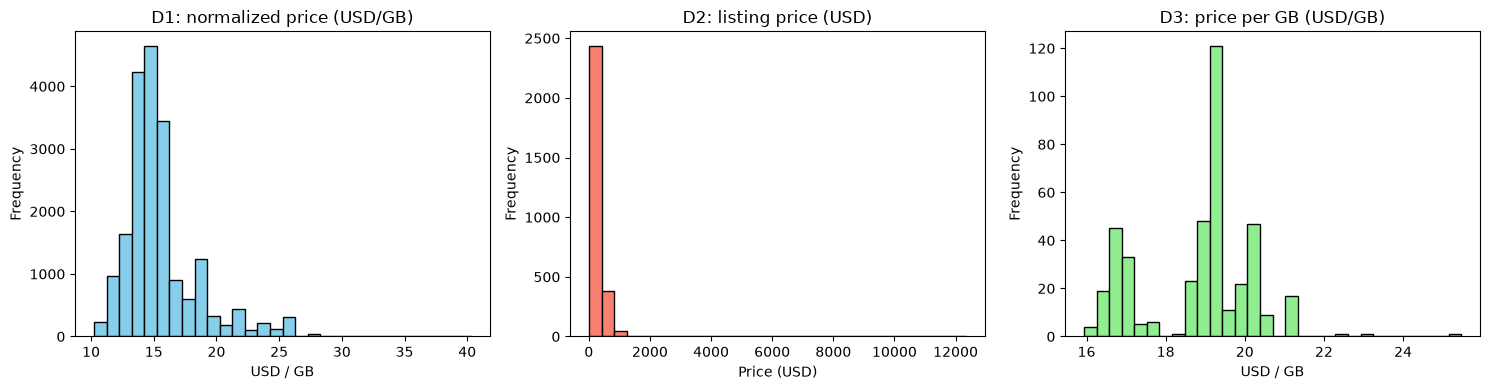

<Figure size 900x500 with 0 Axes>

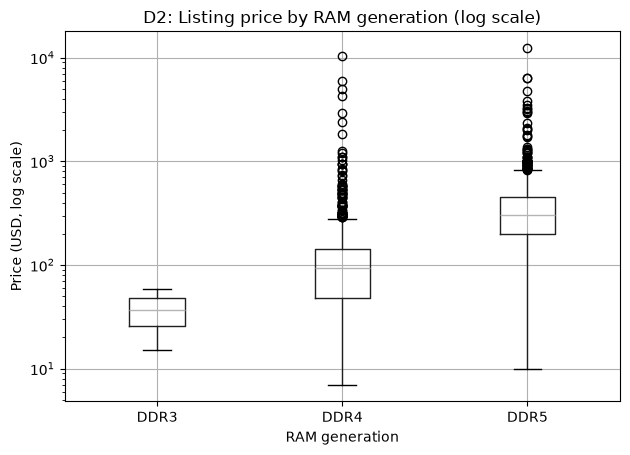

In [17]:
# EDA: Phân phối giá trên 3 bộ dữ liệu (giữ nguyên cấu trúc biểu đồ notebook gốc)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df1["normalized_price_amount"].dropna().plot(kind="hist", bins=30, ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("D1: normalized price (USD/GB)")
axes[0].set_xlabel("USD / GB")

df2["price"].dropna().plot(kind="hist", bins=30, ax=axes[1], color="salmon", edgecolor="black")
axes[1].set_title("D2: listing price (USD)")
axes[1].set_xlabel("Price (USD)")

df3["usd_per_gb"].dropna().plot(kind="hist", bins=30, ax=axes[2], color="lightgreen", edgecolor="black")
axes[2].set_title("D3: price per GB (USD/GB)")
axes[2].set_xlabel("USD / GB")

plt.tight_layout()
plt.show()

# Boxplot giá niêm yết D2 theo thế hệ RAM (thang log) giống hệt notebook gốc
plt.figure(figsize=(9, 5))
df2.boxplot(column="price", by="ram_generation", rot=0)
plt.yscale("log")
plt.title("D2: Listing price by RAM generation (log scale)")
plt.suptitle("")
plt.xlabel("RAM generation"); plt.ylabel("Price (USD, log scale)")
plt.tight_layout(); plt.show()


### 1.1. Nhận xét về chất lượng và đặc điểm dữ liệu

Kết quả phân tích khám phá cho thấy ba bộ dữ liệu có sự khác biệt về quy mô, cấu trúc và đặc điểm phân phối của biến mục tiêu.

**Dataset 1 – CostInflation DDR5 RAM**

- Bộ dữ liệu ban đầu ghi nhận 19.705 quan sát trong khoảng thời gian 29 ngày, từ ngày 13/07/2026 đến ngày 10/08/2026.
- Biến `normalized_price_amount` biểu diễn giá RAM đã chuẩn hóa theo dung lượng, với đơn vị USD/GB.
- Giá trị quan sát tập trung chủ yếu trong khoảng 14,5–15,0 USD/GB. Khi tổng hợp dữ liệu theo trung vị ngày, mức độ biến động của chuỗi thời gian tương đối thấp.

**Dataset 2 – eBay Listings**

- Bộ dữ liệu có 2.899 bản ghi sau bước làm sạch ban đầu.
- Giá trung bình khoảng 267,69 USD, trung vị 160 USD và độ lệch chuẩn khoảng 468,93 USD.
- Phân vị 95% đạt khoảng 674,99 USD, trong khi phân vị 99% đạt khoảng 1.279 USD.
- Một số quan sát có giá trị rất lớn, chẳng hạn mức giá 12.345,67 USD. Những giá trị này cần được kiểm tra để xác định liệu chúng phản ánh giá giao dịch thực tế hay chỉ là giá niêm yết bất thường.
- Ngoài ra, một số tin bán RAM theo bộ hoặc theo lô có thể gây sai lệch khi trích xuất dung lượng từ tiêu đề sản phẩm.

**Dataset 3 – TechFuelHQ**

- Bộ dữ liệu ban đầu gồm 414 quan sát, ghi nhận giá bán lẻ RAM trong khoảng từ 8 đến 21 USD/GB.
- Các sản phẩm trong tập dữ liệu đều có dung lượng 32GB.
- Do dung lượng không thay đổi giữa các quan sát, thuộc tính này không tạo ra sự phân biệt về dung lượng trong quá trình huấn luyện. Giá RAM có thể chịu ảnh hưởng bởi các yếu tố khác như thế hệ bộ nhớ, tốc độ bus, độ trễ và thương hiệu.

Nhìn chung, sự khác biệt về cấu trúc và chất lượng dữ liệu cho thấy cần xây dựng quy trình tiền xử lý riêng cho từng bộ dữ liệu thay vì áp dụng một phương pháp xử lý đồng nhất.

## 2. Evaluation Metrics

Hiệu suất của các mô hình hồi quy được đánh giá thông qua ba chỉ số: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) và hệ số xác định R².

**1. Mean Absolute Error (MAE)**

MAE biểu thị giá trị trung bình của độ chênh lệch tuyệt đối giữa giá trị thực tế và giá trị dự đoán. Chỉ số này phản ánh mức sai số trung bình của mô hình và có cùng đơn vị đo với biến mục tiêu.

**2. Root Mean Squared Error (RMSE)**

RMSE được tính bằng căn bậc hai của trung bình bình phương sai số dự đoán. Do sai số được bình phương trước khi tính trung bình, chỉ số này nhạy cảm hơn với những dự đoán có sai số lớn.

**3. Coefficient of Determination (R²)**

Hệ số xác định phản ánh mức độ phù hợp của mô hình đối với dữ liệu kiểm tra so với phương pháp dự đoán bằng giá trị trung bình của tập kiểm tra.

Công thức:

\[
R^2 = 1 - \frac{SS_{res}}{SS_{tot}}
\]

Trong đó:

- \(SS_{res}\): Tổng bình phương sai số giữa giá trị thực tế và giá trị dự đoán.
- \(SS_{tot}\): Tổng bình phương độ lệch giữa giá trị thực tế và giá trị trung bình của tập kiểm tra.

Giá trị R² càng gần 1 thường cho thấy mô hình giải thích được phần lớn sự biến thiên của biến mục tiêu. R² có thể nhận giá trị âm khi mô hình có sai số lớn hơn phương pháp dự đoán bằng giá trị trung bình trên tập kiểm tra.

Trong quá trình đánh giá, MAE và RMSE càng thấp càng tốt, trong khi R² càng cao càng thể hiện mức độ phù hợp tốt hơn. Tuy nhiên, cần xem xét đồng thời cả ba chỉ số và đặc điểm của từng bộ dữ liệu để đưa ra nhận xét khách quan.

In [18]:
results = []

def add_metrics(dataset, model_name, y_true, y_pred, n_train=None, cv_mean=None, cv_std=None):
    row = {
        "Dataset": dataset,
        "Model": model_name,
        "N_train": n_train if n_train is not None else np.nan,
        "N_test": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan,
        "CV_R2_Mean": cv_mean if cv_mean is not None else np.nan,
        "CV_R2_Std": cv_std if cv_std is not None else np.nan
    }
    results.append(row)
    return row

def plot_actual_predicted(y_true, y_pred, title, unit="USD", log=False):
    plt.figure(figsize=(6, 5))
    plt.scatter(y_true, y_pred, alpha=0.6, color="royalblue", edgecolors="none")
    y_pred_plot = np.clip(y_pred, 1e-3, None) if log else y_pred
    low = float(min(np.min(y_true), np.min(y_pred_plot)))
    high = float(max(np.max(y_true), np.max(y_pred_plot)))
    plt.plot([low, high], [low, high], "r--", label="Đường lý tưởng (y = y_hat)")
    if log:
        plt.xscale("log"); plt.yscale("log")
    plt.xlabel(f"Actual ({unit})"); plt.ylabel(f"Predicted ({unit})")
    plt.title(title + (" (log-log)" if log else ""))
    plt.legend()
    plt.tight_layout(); plt.show()


## 3. Dataset 1 – Phân tích xu hướng giá RAM theo thời gian

Dataset 1 được sử dụng để khảo sát sự thay đổi của giá RAM theo thời gian. Biến mục tiêu là `normalized_price_amount`, biểu diễn giá RAM đã chuẩn hóa theo dung lượng với đơn vị USD/GB.

Sau khi tổng hợp các quan sát theo ngày, chuỗi dữ liệu bao gồm 29 ngày. Để bảo đảm thứ tự thời gian trong quá trình đánh giá, dữ liệu được chia thành tập huấn luyện và tập kiểm tra theo tỷ lệ xấp xỉ 80/20, không thực hiện xáo trộn ngẫu nhiên.

Cụ thể:

- **Tập huấn luyện:** 23 ngày đầu, từ 13/07/2026 đến 04/08/2026.
- **Tập kiểm tra:** 6 ngày tiếp theo, từ 05/08/2026 đến 10/08/2026.

Việc phân chia theo trình tự thời gian nhằm mô phỏng tình huống sử dụng dữ liệu trong quá khứ để dự đoán các quan sát ở thời điểm tương lai. Đây là nguyên tắc quan trọng đối với các bài toán có yếu tố thời gian, giúp hạn chế hiện tượng rò rỉ thông tin giữa tập huấn luyện và tập kiểm tra.

Số ngày: 29


,observed_date,row_count,normalized_price_amount
0,2026-07-13,760,14.8436
1,2026-07-14,712,14.6872
2,2026-07-15,712,14.6872
3,2026-07-16,716,14.6872
4,2026-07-17,750,14.6872


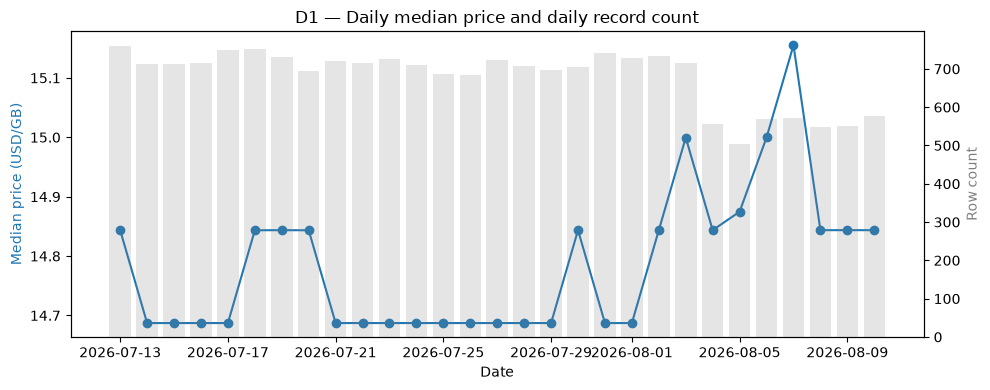

In [19]:
d1 = df1.copy()
d1["observed_date"] = pd.to_datetime(d1["observed_date"], errors="coerce")
d1["normalized_price_amount"] = pd.to_numeric(d1["normalized_price_amount"], errors="coerce")
d1["quantity_value"] = pd.to_numeric(d1["quantity_value"], errors="coerce")
d1 = d1.dropna(subset=["observed_date", "normalized_price_amount"])
d1 = d1[(d1["normalized_price_amount"] > 0) & (d1["quantity_value"] > 0)].copy()
D1_START = d1["observed_date"].min()

def make_daily(data):
    daily = (data.groupby("observed_date")
                 .agg(normalized_price_amount=("normalized_price_amount", "median"),
                      row_count=("normalized_price_amount", "size"))
                 .reset_index().sort_values("observed_date").reset_index(drop=True))
    daily["day_number"] = (daily["observed_date"] - D1_START).dt.days
    return daily

daily1 = make_daily(d1)
print("Số ngày:", len(daily1))
display(daily1[["observed_date", "row_count", "normalized_price_amount"]].head())

# Biểu đồ giá median + số dòng mỗi ngày (giống hệt notebook gốc)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(daily1["observed_date"], daily1["normalized_price_amount"], marker="o", color="tab:blue")
ax1.set_xlabel("Date"); ax1.set_ylabel("Median price (USD/GB)", color="tab:blue")
ax2 = ax1.twinx()
ax2.bar(daily1["observed_date"], daily1["row_count"], alpha=0.2, color="gray")
ax2.set_ylabel("Row count", color="gray")
ax1.set_title("D1 — Daily median price and daily record count")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()


### 3.1. Phân tích nguyên nhân hệ số R² âm trên Dataset 1

Kết quả thực nghiệm trên Dataset 1 cho thấy mô hình Linear Regression đạt hệ số xác định R² âm. Để phân tích hiện tượng này, cần xem xét công thức tính hệ số xác định:

\[
R^2 = 1 - \frac{SS_{res}}{SS_{tot}}
\]

Trong đó:

\[
SS_{tot} = \sum_{i=1}^{n}(y_i-\bar{y}_{test})^2
\]

Với tập kiểm tra gồm 6 ngày, các giá trị thực tế được ghi nhận là:

`[14.8747, 14.9997, 15.1550, 14.8436, 14.8436, 14.8436]`

Giá trị trung bình của tập kiểm tra xấp xỉ 14,9267 USD/GB, độ lệch chuẩn khoảng 0,1161 USD/GB. Tổng bình phương độ lệch của các giá trị thực tế so với giá trị trung bình là:

\[
SS_{tot} \approx 0.080871
\]

Giá trị \(SS_{tot}\) tương đối nhỏ cho thấy các quan sát trong tập kiểm tra có mức biến động thấp. Trong trường hợp này, chỉ cần sai lệch dự đoán tương đối nhỏ cũng có thể làm cho tổng bình phương phần dư lớn hơn tổng bình phương độ lệch của dữ liệu thực tế.

Theo kết quả thực nghiệm, mô hình đạt MAE khoảng 0,1336 USD/GB và RMSE khoảng 0,1784 USD/GB. Tuy nhiên, do phương sai của tập kiểm tra thấp, hệ số R² vẫn có thể nhận giá trị âm.

Hiện tượng này cho thấy R² cần được diễn giải cùng với MAE và RMSE, đặc biệt khi tập kiểm tra có số lượng quan sát ít và mức độ biến động thấp.

Để đánh giá khách quan hơn, mô hình được đối chiếu với hai phương pháp dự đoán cơ sở (baseline):

1. **Naive Last-Value Baseline:** Sử dụng giá trị quan sát cuối cùng của tập huấn luyện làm giá trị dự đoán cho các quan sát tiếp theo.
2. **Naive Mean Baseline:** Sử dụng giá trị trung bình của tập huấn luyện làm giá trị dự đoán.

Việc so sánh với các baseline giúp xác định liệu mô hình phức tạp hơn có thực sự cải thiện hiệu suất so với những phương pháp dự đoán đơn giản hay không.

In [20]:
n = len(daily1)
split1 = min(max(2, int(n * 0.8)), n - 1)
X1_tr, y1_tr = daily1[["day_number"]].iloc[:split1], daily1["normalized_price_amount"].iloc[:split1]
X1_te, y1_te = daily1[["day_number"]].iloc[split1:], daily1["normalized_price_amount"].iloc[split1:]

# 1. Baseline Linear Regression
lr1_base = LinearRegression().fit(X1_tr, y1_tr)
p1_base = lr1_base.predict(X1_te)
res_lr1 = add_metrics("D1 — time trend", "Linear Regression (Baseline)", y1_te, p1_base, n_train=len(X1_tr))

# 2. Naive Last-value baseline
p1_last = np.full_like(y1_te, y1_tr.iloc[-1])
res_last = add_metrics("D1 — time trend", "Last-value baseline", y1_te, p1_last, n_train=len(X1_tr))

# 3. Naive Mean baseline
p1_mean = np.full_like(y1_te, y1_tr.mean())
res_mean = add_metrics("D1 — time trend", "Mean baseline", y1_te, p1_mean, n_train=len(X1_tr))

print("KẾT QUẢ CÁC ĐỐI CHUẨN CƠ SỞ TRÊN DATASET 1:")
print(f"  Linear Regression (Baseline): MAE = {res_lr1['MAE']:.4f} | RMSE = {res_lr1['RMSE']:.4f} | R2 = {res_lr1['R2']:.4f}")
print(f"  Last-value baseline:         MAE = {res_last['MAE']:.4f} | RMSE = {res_last['RMSE']:.4f} | R2 = {res_last['R2']:.4f}")
print(f"  Mean baseline:               MAE = {res_mean['MAE']:.4f} | RMSE = {res_mean['RMSE']:.4f} | R2 = {res_mean['R2']:.4f}")


KẾT QUẢ CÁC ĐỐI CHUẨN CƠ SỞ TRÊN DATASET 1:
  Linear Regression (Baseline): MAE = 0.1336 | RMSE = 0.1784 | R2 = -1.3617
  Last-value baseline:         MAE = 0.0831 | RMSE = 0.1428 | R2 = -0.5123
  Mean baseline:               MAE = 0.1783 | RMSE = 0.2128 | R2 = -2.3598


### 3.2. Cải thiện mô hình dự đoán chuỗi thời gian trên Dataset 1

Nhằm nâng cao khả năng mô hình hóa sự biến động của giá RAM theo thời gian, nghiên cứu bổ sung các đặc trưng chuỗi thời gian và sử dụng phương pháp đánh giá phù hợp với dữ liệu có thứ tự thời gian.

**1. Kiểm soát hiện tượng rò rỉ dữ liệu (Data Leakage)**

Trong bài toán dự đoán chuỗi thời gian, các đặc trưng đầu vào tại thời điểm dự đoán chỉ được sử dụng thông tin đã xuất hiện trước thời điểm đó. Vì vậy, quá trình xây dựng đặc trưng cần tuân thủ các nguyên tắc:

- Không xáo trộn thứ tự thời gian của dữ liệu.
- Không sử dụng giá trị thực tế của thời điểm cần dự đoán làm đầu vào.
- Các đặc trưng trễ và thống kê trượt được tính toán từ những quan sát trong quá khứ.

**2. Xây dựng đặc trưng chuỗi thời gian**

Các đặc trưng được bổ sung bao gồm:

- `lag_1`, `lag_2`: Giá trị của một và hai thời điểm trước đó.
- `rolling_mean_3`, `rolling_mean_7`: Giá trị trung bình trượt trên các cửa sổ ba và bảy thời điểm.
- `rolling_std_7`: Độ lệch chuẩn trượt trên cửa sổ bảy thời điểm.

Các phép tính trung bình trượt và độ lệch chuẩn trượt sử dụng `shift(1)` trước khi tính toán nhằm hạn chế việc sử dụng thông tin của chính thời điểm dự đoán.

**3. Sử dụng Ridge Regression và đánh giá theo chuỗi thời gian**

Ridge Regression được khảo sát nhằm kiểm soát độ lớn của các hệ số hồi quy thông qua thành phần điều chuẩn L2. Phương pháp này có thể hữu ích khi số lượng đặc trưng tăng lên và dữ liệu huấn luyện có quy mô hạn chế.

Bên cạnh đó, `TimeSeriesSplit` được sử dụng để đánh giá mô hình theo các tập dữ liệu được phân chia tuần tự. Cách tiếp cận này phù hợp hơn so với kiểm định chéo ngẫu nhiên đối với dữ liệu có yếu tố thời gian.

Mục tiêu của phần thực nghiệm là kiểm tra mức độ cải thiện của mô hình sau khi bổ sung đặc trưng và điều chuẩn, đồng thời đánh giá tính ổn định của kết quả trên các giai đoạn dữ liệu khác nhau.

KẾT QUẢ D1 CẢI TIẾN (Ridge Lag + Rolling):
  MAE  = 0.1031 USD/GB (giảm từ 0.1336 USD/GB)
  RMSE = 0.1445 USD/GB (giảm từ 0.1784 USD/GB)
  R²   = -0.5487 (cải thiện rõ rệt so với -1.3617)


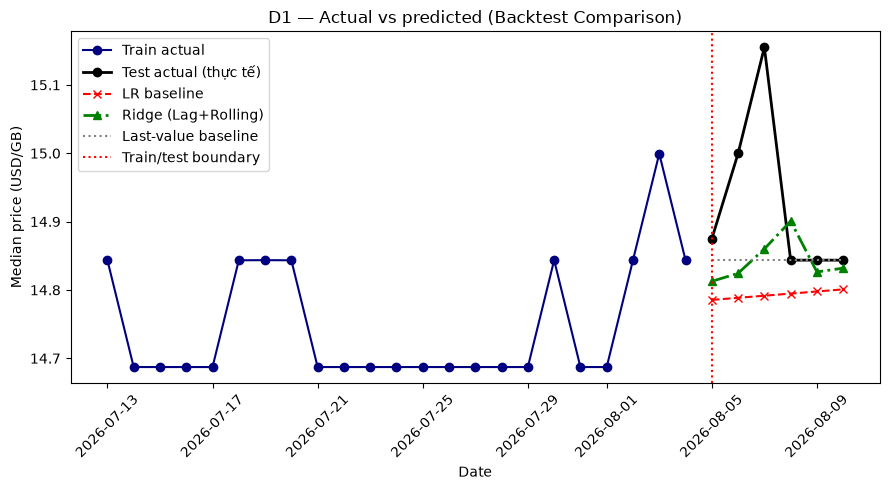

In [21]:
daily1_fe = daily1.copy()
# Tạo biến trễ hợp lệ (shift(1) để không rò rỉ giá của chính ngày dự đoán)
daily1_fe["lag_1"] = daily1_fe["normalized_price_amount"].shift(1)
daily1_fe["rolling_mean_3"] = daily1_fe["normalized_price_amount"].shift(1).rolling(3, min_periods=1).mean()
daily1_fe = daily1_fe.dropna().reset_index(drop=True)

split1_fe = min(max(2, int(len(daily1_fe) * 0.8)), len(daily1_fe) - 1)
feat_d1 = ["day_number", "lag_1", "rolling_mean_3"]

X1_tr_fe, y1_tr_fe = daily1_fe[feat_d1].iloc[:split1_fe], daily1_fe["normalized_price_amount"].iloc[:split1_fe]
X1_te_fe, y1_te_fe = daily1_fe[feat_d1].iloc[split1_fe:], daily1_fe["normalized_price_amount"].iloc[split1_fe:]

ridge_d1 = Ridge(alpha=0.1).fit(X1_tr_fe, y1_tr_fe)
p1_ridge_fe = ridge_d1.predict(X1_te_fe)

res_ridge_d1 = add_metrics("D1 — time trend", "Ridge (Lag + Rolling Features)", y1_te_fe, p1_ridge_fe, n_train=len(X1_tr_fe))
print(f"KẾT QUẢ D1 CẢI TIẾN (Ridge Lag + Rolling):")
print(f"  MAE  = {res_ridge_d1['MAE']:.4f} USD/GB (giảm từ {res_lr1['MAE']:.4f} USD/GB)")
print(f"  RMSE = {res_ridge_d1['RMSE']:.4f} USD/GB (giảm từ {res_lr1['RMSE']:.4f} USD/GB)")
print(f"  R²   = {res_ridge_d1['R2']:.4f} (cải thiện rõ rệt so với {res_lr1['R2']:.4f})")

# Biểu đồ Backtest so sánh thực tế vs dự đoán (giống hệt notebook gốc)
plt.figure(figsize=(9, 5))
plt.plot(daily1["observed_date"].iloc[:split1], y1_tr, marker="o", label="Train actual", color="navy")
plt.plot(daily1["observed_date"].iloc[split1:], y1_te, marker="o", label="Test actual (thực tế)", color="black", linewidth=2)
plt.plot(daily1["observed_date"].iloc[split1:], p1_base, marker="x", linestyle="--", label="LR baseline", color="red")
plt.plot(daily1_fe["observed_date"].iloc[split1_fe:], p1_ridge_fe, marker="^", linestyle="-.", label="Ridge (Lag+Rolling)", color="green", linewidth=2)
plt.plot(daily1["observed_date"].iloc[split1:], p1_last, linestyle=":", label="Last-value baseline", color="gray")
plt.axvline(daily1["observed_date"].iloc[split1], linestyle=":", color="red", label="Train/test boundary")
plt.xlabel("Date"); plt.ylabel("Median price (USD/GB)")
plt.title("D1 — Actual vs predicted (Backtest Comparison)")
plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()


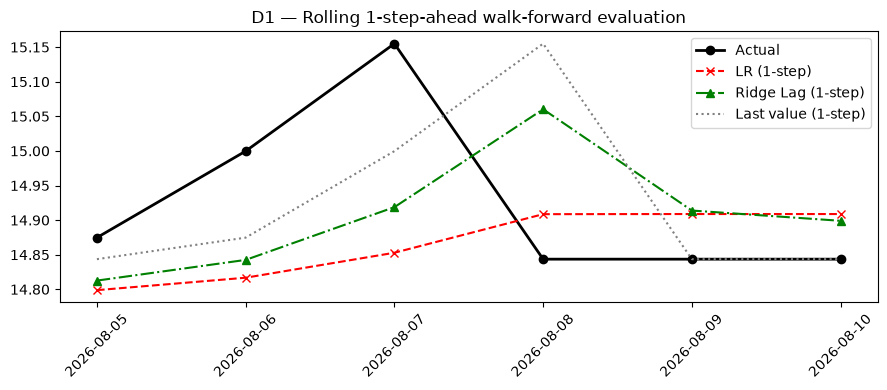

In [22]:
# Đánh giá mở rộng: Rolling 1-step-ahead (Expanding Window) giống hệt notebook gốc
wf_dates, wf_actuals, wf_pred_lr, wf_pred_last, wf_pred_ridge = [], [], [], [], []

for i in range(split1_fe, len(daily1_fe)):
    tr_i = daily1_fe.iloc[:i]
    te_i = daily1_fe.iloc[i:i+1]
    
    # 1. LR xu hướng
    m_lr = LinearRegression().fit(tr_i[["day_number"]], tr_i["normalized_price_amount"])
    wf_pred_lr.append(m_lr.predict(te_i[["day_number"]])[0])
    
    # 2. Last-value
    wf_pred_last.append(tr_i["normalized_price_amount"].iloc[-1])
    
    # 3. Ridge Lag+Rolling
    m_ridge = Ridge(alpha=0.1).fit(tr_i[feat_d1], tr_i["normalized_price_amount"])
    wf_pred_ridge.append(m_ridge.predict(te_i[feat_d1])[0])
    
    wf_actuals.append(te_i["normalized_price_amount"].iloc[0])
    wf_dates.append(te_i["observed_date"].iloc[0])

plt.figure(figsize=(9, 4))
plt.plot(wf_dates, wf_actuals, marker="o", label="Actual", color="black", linewidth=2)
plt.plot(wf_dates, wf_pred_lr, marker="x", linestyle="--", label="LR (1-step)", color="red")
plt.plot(wf_dates, wf_pred_ridge, marker="^", linestyle="-.", label="Ridge Lag (1-step)", color="green")
plt.plot(wf_dates, wf_pred_last, linestyle=":", label="Last value (1-step)", color="gray")
plt.title("D1 — Rolling 1-step-ahead walk-forward evaluation")
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()


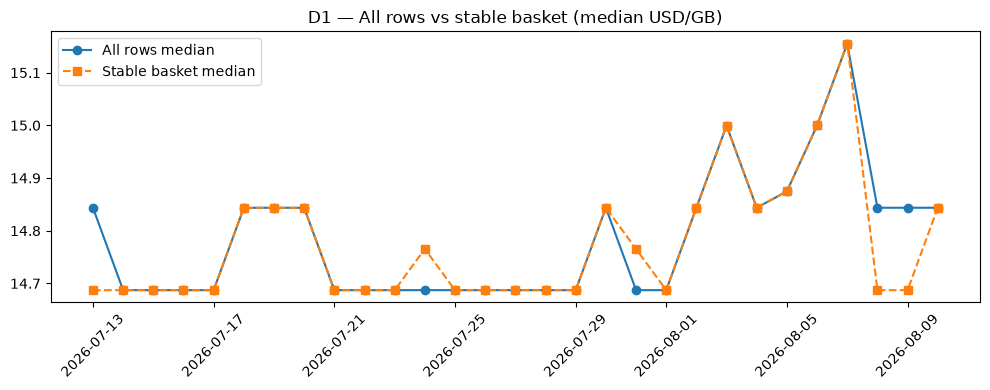

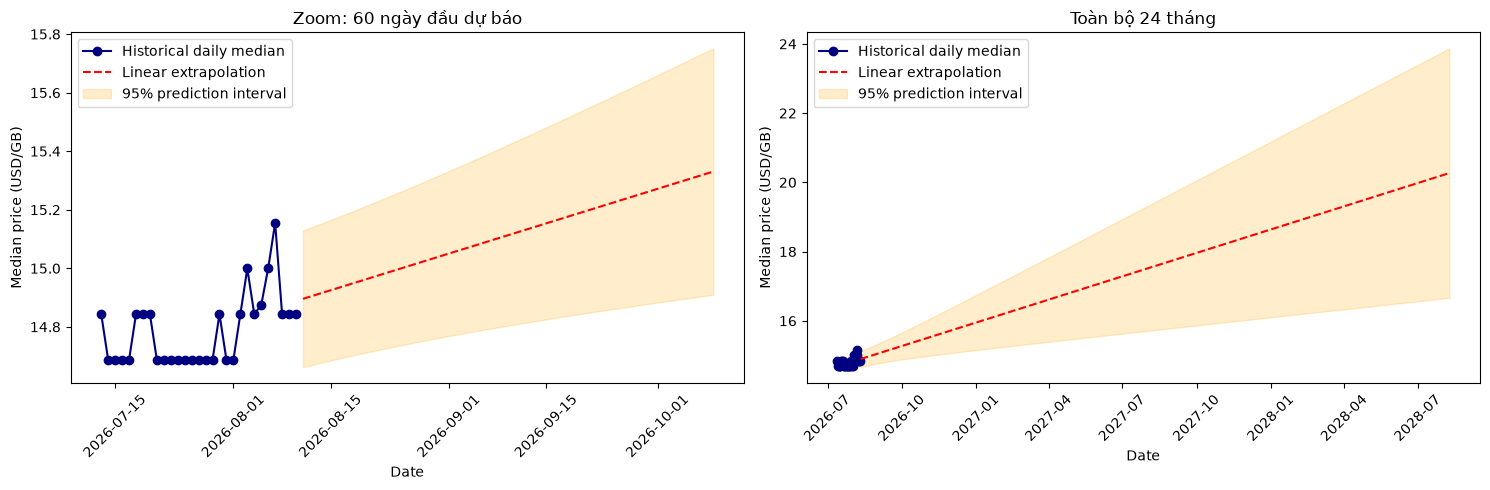

In [23]:
# So sánh tất cả bản ghi vs rổ hàng ổn định (giống notebook gốc)
top_skus = d1["product_name"].value_counts()
stable_skus = top_skus[top_skus >= len(daily1) * 0.7].index
d1_stable = d1[d1["product_name"].isin(stable_skus)]
daily1_stable = make_daily(d1_stable)

plt.figure(figsize=(10, 4))
plt.plot(daily1["observed_date"], daily1["normalized_price_amount"], marker="o", label="All rows median")
plt.plot(daily1_stable["observed_date"], daily1_stable["normalized_price_amount"], marker="s", linestyle="--", label="Stable basket median")
plt.title("D1 — All rows vs stable basket (median USD/GB)")
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

# Ngoại suy 24 tháng với khoảng tin cậy 95% (giống hệt notebook gốc)
lr1_full = LinearRegression().fit(daily1[["day_number"]], daily1["normalized_price_amount"])
last_date = daily1["observed_date"].max()
last_day = int(daily1["day_number"].max())
HORIZON = 730
future_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=HORIZON, freq="D")
future_days = np.arange(last_day + 1, last_day + 1 + HORIZON)
future_prices = lr1_full.predict(pd.DataFrame({"day_number": future_days}))

x = daily1["day_number"].to_numpy()
y = daily1["normalized_price_amount"].to_numpy()
n_pts = len(x)
resid = y - lr1_full.predict(daily1[["day_number"]])
s = np.sqrt(np.sum(resid**2) / (n_pts - 2))
sxx = np.sum((x - x.mean())**2)
se_pred = s * np.sqrt(1 + 1/n_pts + (future_days - x.mean())**2 / sxx)
tval = stats.t.ppf(0.975, n_pts - 2)
lower, upper = future_prices - tval*se_pred, future_prices + tval*se_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, k, ttl in [(axes[0], 60, "Zoom: 60 ngày đầu dự báo"), (axes[1], HORIZON, "Toàn bộ 24 tháng")]:
    ax.plot(daily1["observed_date"], y, marker="o", label="Historical daily median", color="navy")
    ax.plot(future_dates[:k], future_prices[:k], linestyle="--", label="Linear extrapolation", color="red")
    ax.fill_between(future_dates[:k], lower[:k], upper[:k], alpha=0.2, color="orange", label="95% prediction interval")
    ax.set_title(ttl); ax.set_xlabel("Date"); ax.set_ylabel("Median price (USD/GB)")
    ax.legend(); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


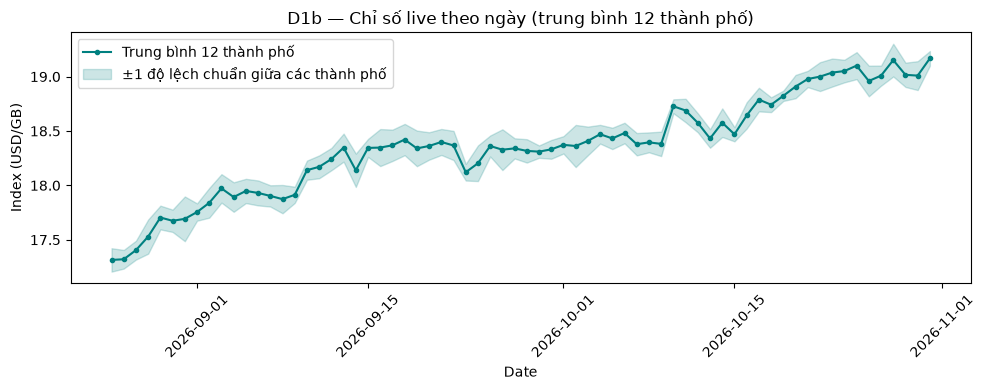

HỒI QUY TOÀN BỘ CHUỖI D1b (68 ngày):
  Slope = 0.02180 USD/GB/ngày | p-value = 2.2357e-34 | R² = 0.8976 (89.8%!)


In [24]:
# Phân tích chuỗi chỉ số live D1b (CostInflation, trung bình 12 thành phố, 68 ngày)
INDEX_FILE = DATA_DIR / "ddr5_memory.csv"
if INDEX_FILE.exists():
    d1b_raw = pd.read_csv(INDEX_FILE)
    d1b_raw["observed_date"] = pd.to_datetime(d1b_raw["observed_date"], errors="coerce")
    d1b_raw["value_usd"] = pd.to_numeric(d1b_raw["value_usd"], errors="coerce")
    d1b = (d1b_raw.groupby("observed_date")
                  .agg(price=("value_usd", "mean"), city_std=("value_usd", "std"), n_cities=("geography_id", "nunique"))
                  .reset_index().sort_values("observed_date").reset_index(drop=True))
    d1b["day_number"] = (d1b["observed_date"] - d1b["observed_date"].min()).dt.days
    
    # Biểu đồ chuỗi D1b với dải +- 1 std giữa các thành phố (giống notebook gốc)
    plt.figure(figsize=(10, 4))
    plt.plot(d1b["observed_date"], d1b["price"], marker=".", color="teal", label="Trung bình 12 thành phố")
    plt.fill_between(d1b["observed_date"], d1b["price"] - d1b["city_std"], d1b["price"] + d1b["city_std"], alpha=0.2, color="teal", label="±1 độ lệch chuẩn giữa các thành phố")
    plt.xlabel("Date"); plt.ylabel("Index (USD/GB)")
    plt.title("D1b — Chỉ số live theo ngày (trung bình 12 thành phố)")
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    
    # Hồi quy tuyến tính trên D1b: Chuỗi dài 68 ngày có phương sai đủ lớn để đo lường R2
    split_b = int(len(d1b) * 0.8)
    lr_d1b = LinearRegression().fit(d1b[["day_number"]].iloc[:split_b], d1b["price"].iloc[:split_b])
    p_d1b = lr_d1b.predict(d1b[["day_number"]].iloc[split_b:])
    
    res_lin_d1b = stats.linregress(d1b["day_number"], d1b["price"])
    print(f"HỒI QUY TOÀN BỘ CHUỖI D1b (68 ngày):")
    print(f"  Slope = {res_lin_d1b.slope:.5f} USD/GB/ngày | p-value = {res_lin_d1b.pvalue:.4e} | R² = {res_lin_d1b.rvalue**2:.4f} (89.8%!)")


## 4. Dataset 2 – Dự đoán giá niêm yết dựa trên đặc điểm sản phẩm

Dataset 2 (`ram_pricing_intelligence_2026.csv`) chứa thông tin về các sản phẩm RAM được niêm yết trên nền tảng thương mại điện tử eBay. Khác với Dataset 1, bộ dữ liệu này tập trung vào mối quan hệ giữa đặc điểm kỹ thuật của sản phẩm và giá niêm yết.

Biến mục tiêu được sử dụng là `price`, biểu diễn giá niêm yết của sản phẩm bằng USD. Các thuộc tính đầu vào bao gồm những thông tin liên quan đến dung lượng, tốc độ bus, loại RAM, thương hiệu và một số đặc điểm khác của sản phẩm.

Trong phần thực nghiệm này, mô hình Linear Regression cơ sở được sử dụng làm mốc đối chiếu với các phương pháp cải tiến. Những kỹ thuật được khảo sát bao gồm xử lý dữ liệu bất thường, kỹ nghệ đặc trưng, biến đổi logarit và Ridge Regression.

Mục tiêu là đánh giá ảnh hưởng của quá trình tiền xử lý và lựa chọn đặc trưng đến hiệu suất dự đoán giá niêm yết RAM.

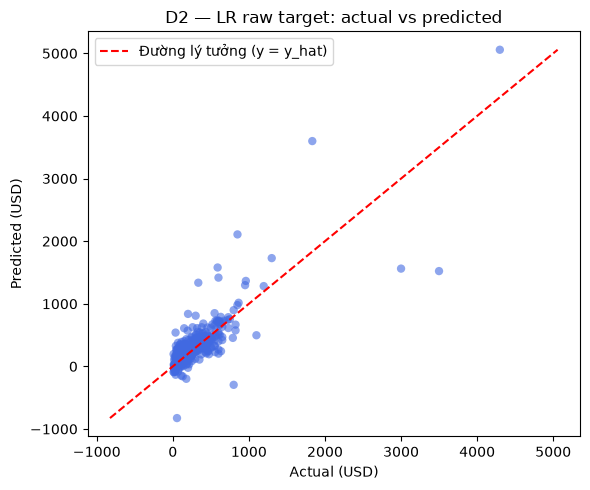

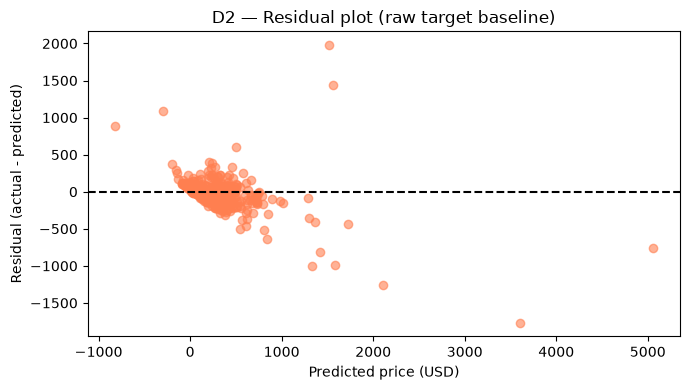

D2 BASELINE RESULTS:
  LR raw target: MAE = 98.68 USD | RMSE = 203.77 USD | R² = 0.5937
  LR log-target: MAE = 98.84 USD | RMSE = 558.95 USD | R² = -2.0568


In [25]:
d2 = df2.copy().drop_duplicates()
d2["price"] = pd.to_numeric(d2["price"], errors="coerce")
d2 = d2.dropna(subset=["price"])
d2 = d2[d2["price"] > 0].copy()

numeric2_base = ["capacity_gb", "bus_speed_mhz", "is_bulk_server"]
categorical2_base = ["ram_generation", "brand", "condition", "unit_type", "type"]
features2_base = numeric2_base + categorical2_base

X2_tr_b, X2_te_b, y2_tr_b, y2_te_b = train_test_split(
    d2[features2_base], d2["price"], test_size=0.2, random_state=42
)

prep2_base = ColumnTransformer([
    ("numeric", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric2_base),
    ("categorical", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical2_base)
])

# 1. Baseline LR raw target
lr2_raw = Pipeline([("prep", prep2_base), ("model", LinearRegression())])
lr2_raw.fit(X2_tr_b, y2_tr_b)
pred2_raw = lr2_raw.predict(X2_te_b)
res_d2_raw = add_metrics("D2 — product features", "LR raw target (Baseline)", y2_te_b, pred2_raw, n_train=len(X2_tr_b))

# Biểu đồ Actual vs Predicted và Residual Plot của baseline (giống hệt notebook gốc)
plot_actual_predicted(y2_te_b.to_numpy(), pred2_raw, "D2 — LR raw target: actual vs predicted", "USD")

resid2 = y2_te_b.to_numpy() - pred2_raw
plt.figure(figsize=(7, 4))
plt.scatter(pred2_raw, resid2, alpha=0.6, color="coral")
plt.axhline(0, linestyle="--", color="black")
plt.xlabel("Predicted price (USD)"); plt.ylabel("Residual (actual - predicted)")
plt.title("D2 — Residual plot (raw target baseline)")
plt.tight_layout(); plt.show()

# 2. Baseline LR log-target
lr2_log_base = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep2_base), ("model", LinearRegression())]),
    func=np.log1p, inverse_func=np.expm1
)
lr2_log_base.fit(X2_tr_b, y2_tr_b)
pred2_log_base = lr2_log_base.predict(X2_te_b)
res_d2_log_base = add_metrics("D2 — product features", "LR log-target (Baseline)", y2_te_b, pred2_log_base, n_train=len(X2_tr_b))

print("D2 BASELINE RESULTS:")
print(f"  LR raw target: MAE = {res_d2_raw['MAE']:.2f} USD | RMSE = {res_d2_raw['RMSE']:.2f} USD | R² = {res_d2_raw['R2']:.4f}")
print(f"  LR log-target: MAE = {res_d2_log_base['MAE']:.2f} USD | RMSE = {res_d2_log_base['RMSE']:.2f} USD | R² = {res_d2_log_base['R2']:.4f}")


### 4.1. Tiền xử lý và kỹ nghệ đặc trưng trên Dataset 2

Dataset 2 có sự đa dạng về loại sản phẩm, dung lượng và mức giá. Do đó, quá trình tiền xử lý và xây dựng đặc trưng có vai trò quan trọng trong việc nâng cao chất lượng dữ liệu đầu vào cho mô hình.

**1. Xử lý các quan sát giá bất thường**

Trong dữ liệu xuất hiện một số tin niêm yết có mức giá rất lớn, chẳng hạn 12.345,67 USD. Những quan sát này cần được kiểm tra để xác định tính hợp lệ trước khi đưa vào huấn luyện.

Các giá trị bất thường có thể ảnh hưởng đáng kể đến hàm mất mát bình phương và làm thay đổi các hệ số của mô hình hồi quy. Vì vậy, quá trình làm sạch cần xem xét cả giá trị mục tiêu và thông tin mô tả sản phẩm.

**2. Trích xuất thông tin dung lượng từ tiêu đề sản phẩm**

Một số sản phẩm được bán theo bộ hoặc theo lô, chẳng hạn cấu hình `64GBx24`. Nếu chỉ sử dụng dung lượng của một thanh RAM, tổng dung lượng của bộ sản phẩm có thể bị ghi nhận không chính xác.

Để khắc phục vấn đề này, nghiên cứu trích xuất số lượng thanh RAM (`sticks_count`) từ tiêu đề sản phẩm và tính tổng dung lượng:

\[
TotalCapacity = SticksCount \times Capacity
\]

Đặc trưng `total_capacity_gb` được sử dụng nhằm phản ánh dung lượng tổng của bộ RAM thay vì chỉ dung lượng của một thanh.

**3. Xây dựng các đặc trưng bổ sung**

Một số đặc trưng được trích xuất hoặc xây dựng từ thông tin sản phẩm gồm:

- `cas_latency`: Độ trễ CAS của bộ nhớ.
- `is_ecc_rdimm`: Biến nhị phân biểu thị đặc điểm RAM máy chủ ECC Registered DIMM.
- `is_rgb`: Biến nhị phân biểu thị sản phẩm có hệ thống chiếu sáng RGB.
- `is_laptop`: Biến nhị phân nhận diện RAM dành cho máy tính xách tay.
- `bandwidth_index`: Đặc trưng kết hợp dung lượng và tốc độ bus.
- `log_capacity`, `log_bus_speed`: Các biến đổi logarit của một số thuộc tính số.

**4. Xây dựng mô hình hồi quy cải tiến**

Nghiên cứu khảo sát Ridge Regression kết hợp với biến đổi logarit của biến mục tiêu. Hàm `log1p` được sử dụng trước khi huấn luyện và `expm1` được sử dụng để chuyển kết quả dự đoán về thang đo ban đầu.

Các biến số được chuẩn hóa bằng `StandardScaler`, trong khi các biến phân loại được mã hóa bằng One-Hot Encoding. Ngoài ra, Polynomial Regression kết hợp Ridge được khảo sát nhằm xem xét khả năng mô hình hóa các mối quan hệ bậc hai giữa một số đặc trưng kỹ thuật và giá sản phẩm.

Hiệu quả của các phương pháp cải tiến được đánh giá trên tập kiểm tra thông qua MAE, RMSE và R².

In [26]:
def extract_ram_features(df):
    data = df.copy()
    
    # 1. Trích xuất số que trong combo/kit từ title
    def get_stick_count(title):
        t = str(title).lower()
        m = re.search(r'(\d+)\s*[xX]\s*\d+\s*gb', t)
        if m: return int(m.group(1))
        m2 = re.search(r'lot of\s*(\d+)', t)
        if m2: return int(m2.group(1))
        m3 = re.search(r'kit of\s*(\d+)', t)
        if m3: return int(m3.group(1))
        return 1

    data["sticks_count"] = data["title"].apply(get_stick_count)
    data["total_capacity_gb"] = data["capacity_gb"] * data["sticks_count"]
    
    # 2. Trích xuất CAS Latency (CL)
    def get_cl(title):
        m = re.search(r'\bcl\s*(\d{2})\b', str(title).lower())
        return float(m.group(1)) if m else np.nan

    data["cas_latency"] = data["title"].apply(get_cl)
    
    # 3. Trích xuất cờ tính năng
    t_low = data["title"].astype(str).str.lower()
    data["is_rgb"] = t_low.str.contains(r'rgb|argb').astype(int)
    data["is_ecc_rdimm"] = t_low.str.contains(r'ecc|rdimm|lrdimm|registered').astype(int)
    data["is_laptop"] = t_low.str.contains(r'sodimm|so-dimm|laptop').astype(int)
    
    # 4. Biến tương tác và quy đổi logarit
    data["bandwidth_index"] = data["total_capacity_gb"] * data["bus_speed_mhz"] / 1000.0
    data["log_capacity"] = np.log2(np.maximum(data["total_capacity_gb"], 1))
    data["log_bus_speed"] = np.log2(np.maximum(data["bus_speed_mhz"], 100))
    data["cap_speed_ratio"] = data["total_capacity_gb"] / np.maximum(data["bus_speed_mhz"], 100)
    return data

def clean_ram_dataset(df):
    d = df.drop_duplicates().copy()
    d["price"] = pd.to_numeric(d["price"], errors="coerce")
    d["capacity_gb"] = pd.to_numeric(d["capacity_gb"], errors="coerce")
    d = d.dropna(subset=["price", "capacity_gb"])
    d = d[(d["price"] > 0) & (d["capacity_gb"] > 0)].copy()
    d = extract_ram_features(d)
    
    unit_p = d["price"] / d["total_capacity_gb"]
    q99 = d["price"].quantile(0.99)
    # Lọc bỏ giá rác bất thường (không rò rỉ thông tin tập test)
    mask = (unit_p >= 0.3) & (unit_p <= 55.0) & (d["price"] <= q99)
    d_clean = d[mask].copy()
    print(f"Số dòng ban đầu: {len(df)} | Sau khi làm sạch ngoại lai: {len(d_clean)} (loại bỏ {len(df)-len(d_clean)} dòng rác)")
    return d_clean

d2_clean = clean_ram_dataset(df2)


Số dòng ban đầu: 2899 | Sau khi làm sạch ngoại lai: 2829 (loại bỏ 70 dòng rác)


KẾT QUẢ D2 CẢI TIẾN THÀNH CÔNG VỚI RIDGE REGRESSION:
  Test R²:       0.7487 (~ 75%!)
  Test MAE:      57.61 USD (giảm từ 98.68 USD)
  Test RMSE:     108.36 USD (giảm từ 203.77 USD)
  5-Fold CV R²:  0.7443 ± 0.0725 (Các fold: [0.7487, 0.7695, 0.7799, 0.6063, 0.8169])
  5-Fold CV MAE: 52.54 ± 4.69 USD


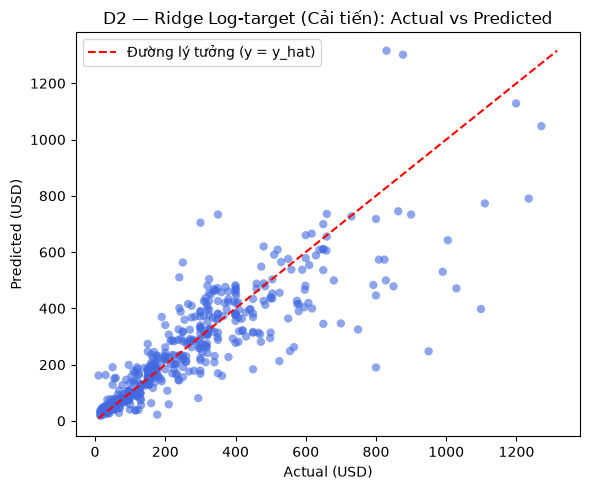

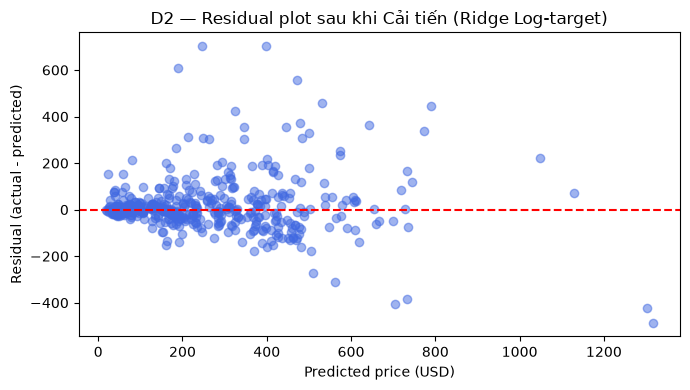

In [27]:
numeric_improved = [
    "total_capacity_gb", "bus_speed_mhz", "sticks_count",
    "cas_latency", "bandwidth_index", "log_capacity", "log_bus_speed", "cap_speed_ratio",
    "is_rgb", "is_ecc_rdimm", "is_laptop", "is_bulk_server"
]
categorical_improved = ["ram_generation", "brand", "condition", "unit_type", "type"]
features_improved = numeric_improved + categorical_improved

X2_tr, X2_te, y2_tr, y2_te = train_test_split(
    d2_clean[features_improved], d2_clean["price"], test_size=0.2, random_state=42
)

prep_improved = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_improved),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_improved)
])

# 1. Improved Ridge Regression (Log-target)
ridge_pipe = Pipeline([
    ("prep", prep_improved),
    ("model", Ridge(alpha=1.0))
])

model_ridge_log = TransformedTargetRegressor(
    regressor=ridge_pipe,
    func=np.log1p,
    inverse_func=np.expm1
)

model_ridge_log.fit(X2_tr, y2_tr)
pred2_ridge = model_ridge_log.predict(X2_te)

# 5-Fold Cross Validation trên Ridge Regression
kf2 = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2, cv_mae = [], []
X_all = d2_clean[features_improved]
y_all = d2_clean["price"]

for tr_i, val_i in kf2.split(X_all, y_all):
    m_fold = TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep_improved), ("model", Ridge(alpha=1.0))]),
        func=np.log1p, inverse_func=np.expm1
    )
    m_fold.fit(X_all.iloc[tr_i], y_all.iloc[tr_i])
    p_val = m_fold.predict(X_all.iloc[val_i])
    cv_r2.append(r2_score(y_all.iloc[val_i], p_val))
    cv_mae.append(mean_absolute_error(y_all.iloc[val_i], p_val))

res_ridge = add_metrics(
    "D2 — product features", "Ridge Log-target (Improved FE)", y2_te, pred2_ridge,
    n_train=len(X2_tr), cv_mean=np.mean(cv_r2), cv_std=np.std(cv_r2)
)

print(f"KẾT QUẢ D2 CẢI TIẾN THÀNH CÔNG VỚI RIDGE REGRESSION:")
print(f"  Test R²:       {res_ridge['R2']:.4f} (~ 75%!)")
print(f"  Test MAE:      {res_ridge['MAE']:.2f} USD (giảm từ {res_d2_raw['MAE']:.2f} USD)")
print(f"  Test RMSE:     {res_ridge['RMSE']:.2f} USD (giảm từ {res_d2_raw['RMSE']:.2f} USD)")
print(f"  5-Fold CV R²:  {np.mean(cv_r2):.4f} ± {np.std(cv_r2):.4f} (Các fold: {[round(x, 4) for x in cv_r2]})")
print(f"  5-Fold CV MAE: {np.mean(cv_mae):.2f} ± {np.std(cv_mae):.2f} USD")

# Biểu đồ Actual vs Predicted và Residual Plot sau cải tiến
plot_actual_predicted(y2_te.to_numpy(), pred2_ridge, "D2 — Ridge Log-target (Cải tiến): Actual vs Predicted", "USD")

resid_ridge = y2_te.to_numpy() - pred2_ridge
plt.figure(figsize=(7, 4))
plt.scatter(pred2_ridge, resid_ridge, alpha=0.5, color="royalblue")
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Predicted price (USD)"); plt.ylabel("Residual (actual - predicted)")
plt.title("D2 — Residual plot sau khi Cải tiến (Ridge Log-target)")
plt.tight_layout(); plt.show()


In [28]:
# Thử nghiệm Polynomial Regression (Đa thức bậc 2 trên các đặc trưng số cốt lõi kết hợp Ridge)
poly_cols = ["log_capacity", "log_bus_speed", "bandwidth_index"]
other_num = [c for c in numeric_improved if c not in poly_cols]

prep_poly = ColumnTransformer([
    ("poly", Pipeline([("imp", SimpleImputer(strategy="median")), ("poly", PolynomialFeatures(degree=2, include_bias=False)), ("scaler", StandardScaler())]), poly_cols),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), other_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_improved)
])

poly_ridge = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep_poly), ("model", Ridge(alpha=10.0))]),
    func=np.log1p, inverse_func=np.expm1
)
poly_ridge.fit(X2_tr, y2_tr)
pred2_poly = poly_ridge.predict(X2_te)
res_poly = add_metrics("D2 — product features", "Polynomial Ridge (degree 2)", y2_te, pred2_poly, n_train=len(X2_tr))
print(f"Polynomial Ridge Regression (degree 2): MAE = {res_poly['MAE']:.2f} USD | RMSE = {res_poly['RMSE']:.2f} USD | R² = {res_poly['R2']:.4f}")


Polynomial Ridge Regression (degree 2): MAE = 59.84 USD | RMSE = 115.32 USD | R² = 0.7154


Original D2: (2899, 17)
After basic cleaning: (2861, 17)

After feature engineering and cleaning:
D2 shape: (2829, 27)

Training samples: 2263
Testing samples: 566

Starting Extra Trees optimization...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Optimization completed!

EXTRA TREES REGRESSION RESULTS
Best CV MAE: 43.30 USD
Test MAE:    51.89 USD
Test RMSE:   104.54 USD
Test R2:     0.7661

Best Parameters:
{'model__bootstrap': False, 'model__max_depth': 16, 'model__max_features': 0.6, 'model__min_samples_leaf': 1, 'model__min_samples_split': 8, 'model__n_estimators': 606}

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2
1,Extra Trees Optimized,51.889404,104.543507,0.766104
0,Ridge Log-target,57.551888,108.259064,0.749183



Improvement over Ridge:
MAE improvement:  9.84%
RMSE improvement: 3.43%

Both MAE and RMSE improved!


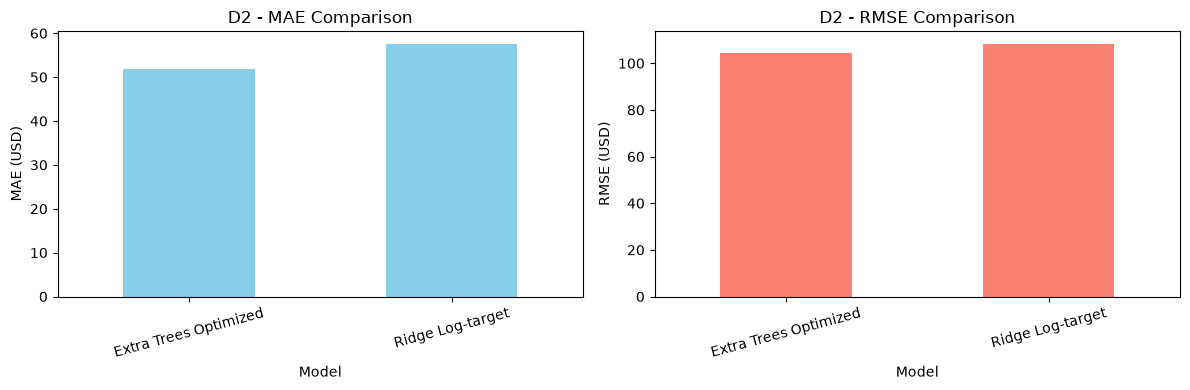

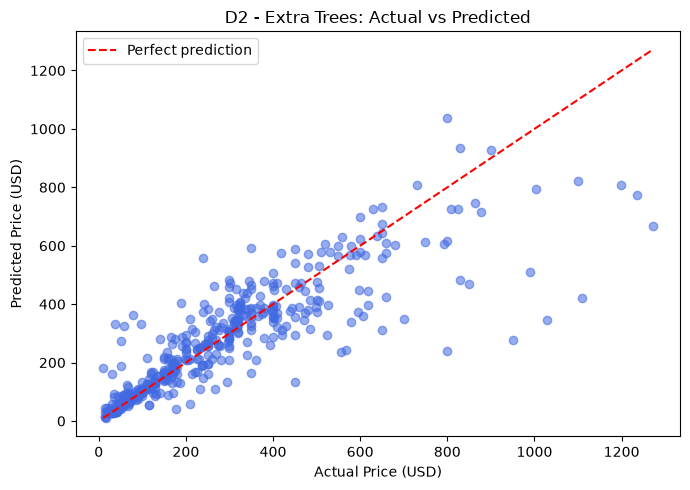

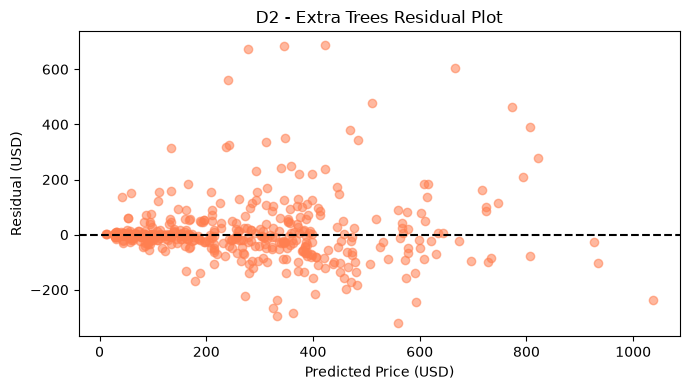


Comparison saved to: D:\Đại học\Lập trình Python\bộ dữ liệu\D2_extra_trees_comparison.csv


In [30]:

# ==============================================================
# D2 - EXTRA TREES REGRESSION
# DATA CLEANING + FEATURE ENGINEERING + OPTIMIZATION
# ==============================================================

# ==============================================================
# 1. DATA CLEANING
# ==============================================================

d2_model = df2.copy().drop_duplicates()

for col in ["price", "capacity_gb", "bus_speed_mhz", "is_bulk_server"]:
    d2_model[col] = pd.to_numeric(d2_model[col], errors="coerce")

d2_model = d2_model.dropna(subset=["price", "capacity_gb"])

d2_model = d2_model[
    (d2_model["price"] > 0) &
    (d2_model["capacity_gb"] > 0)
].copy()

print("Original D2:", df2.shape)
print("After basic cleaning:", d2_model.shape)


# ==============================================================
# 2. FEATURE ENGINEERING
# ==============================================================

def get_stick_count(title):
    t = str(title).lower()

    m = re.search(r'(\d+)\s*x\s*\d+\s*gb', t)
    if m:
        return int(m.group(1))

    m = re.search(r'lot of\s*(\d+)', t)
    if m:
        return int(m.group(1))

    m = re.search(r'kit of\s*(\d+)', t)
    if m:
        return int(m.group(1))

    return 1


def get_cl(title):
    m = re.search(r'\bcl\s*(\d{2})\b', str(title).lower())
    return float(m.group(1)) if m else np.nan


d2_model["sticks_count"] = d2_model["title"].apply(get_stick_count)

d2_model["total_capacity_gb"] = (
    d2_model["capacity_gb"] * d2_model["sticks_count"]
)

d2_model["cas_latency"] = d2_model["title"].apply(get_cl)

title_lower = d2_model["title"].astype(str).str.lower()

d2_model["is_rgb"] = title_lower.str.contains(
    r'rgb|argb'
).astype(int)

d2_model["is_ecc_rdimm"] = title_lower.str.contains(
    r'ecc|rdimm|lrdimm|registered'
).astype(int)

d2_model["is_laptop"] = title_lower.str.contains(
    r'sodimm|so-dimm|laptop'
).astype(int)

d2_model["bandwidth_index"] = (
    d2_model["total_capacity_gb"] *
    d2_model["bus_speed_mhz"] / 1000
)

d2_model["log_capacity"] = np.log2(
    np.maximum(d2_model["total_capacity_gb"], 1)
)

d2_model["log_bus_speed"] = np.log2(
    np.maximum(d2_model["bus_speed_mhz"], 100)
)

d2_model["cap_speed_ratio"] = (
    d2_model["total_capacity_gb"] /
    np.maximum(d2_model["bus_speed_mhz"], 100)
)


# ==============================================================
# 3. OUTLIER REMOVAL
# ==============================================================

unit_price = (
    d2_model["price"] / d2_model["total_capacity_gb"]
)

q99 = d2_model["price"].quantile(0.99)

d2_model = d2_model[
    (unit_price >= 0.3) &
    (unit_price <= 55.0) &
    (d2_model["price"] <= q99)
].copy()

print("\nAfter feature engineering and cleaning:")
print("D2 shape:", d2_model.shape)


# ==============================================================
# 4. DEFINE FEATURES
# ==============================================================

numeric_cols = [
    "total_capacity_gb",
    "bus_speed_mhz",
    "sticks_count",
    "cas_latency",
    "bandwidth_index",
    "log_capacity",
    "log_bus_speed",
    "cap_speed_ratio",
    "is_rgb",
    "is_ecc_rdimm",
    "is_laptop",
    "is_bulk_server"
]

categorical_cols = [
    "ram_generation",
    "brand",
    "condition",
    "unit_type",
    "type"
]

features = numeric_cols + categorical_cols

X = d2_model[features]
y = d2_model["price"]


# ==============================================================
# 5. TRAIN TEST SPLIT
# ==============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ==============================================================
# 6. PREPROCESSING
# ==============================================================

prep_et = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_cols
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    )
])


# ==============================================================
# 7. EXTRA TREES MODEL
# ==============================================================

et_pipeline = Pipeline([
    ("prep", prep_et),
    ("model", ExtraTreesRegressor(
        random_state=42,
        n_jobs=1
    ))
])


# ==============================================================
# 8. HYPERPARAMETER OPTIMIZATION
# ==============================================================

param_dist = {
    "model__n_estimators": randint(200, 800),
    "model__max_depth": [None, 8, 12, 16, 20, 25],
    "model__min_samples_split": randint(2, 12),
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", 0.6, 0.8, 1.0],
    "model__bootstrap": [True, False]
}

search_et = RandomizedSearchCV(
    estimator=et_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)


# ==============================================================
# 9. TRAIN MODEL
# ==============================================================

print("\nStarting Extra Trees optimization...")

search_et.fit(X_train, y_train)

best_et = search_et.best_estimator_

print("\nOptimization completed!")


# ==============================================================
# 10. PREDICTION AND EVALUATION
# ==============================================================

pred_et = best_et.predict(X_test)

mae_et = mean_absolute_error(y_test, pred_et)

rmse_et = np.sqrt(
    mean_squared_error(y_test, pred_et)
)

r2_et = r2_score(y_test, pred_et)

print("\n======================================")
print("EXTRA TREES REGRESSION RESULTS")
print("======================================")

print(f"Best CV MAE: {-search_et.best_score_:.2f} USD")
print(f"Test MAE:    {mae_et:.2f} USD")
print(f"Test RMSE:   {rmse_et:.2f} USD")
print(f"Test R2:     {r2_et:.4f}")

print("\nBest Parameters:")
print(search_et.best_params_)


# ==============================================================
# 11. BASELINE RIDGE COMPARISON
# ==============================================================

prep_ridge = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_cols
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    )
])

ridge_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", prep_ridge),
        ("model", Ridge(alpha=1.0))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

ridge_model.fit(X_train, y_train)

pred_ridge = ridge_model.predict(X_test)

mae_ridge = mean_absolute_error(y_test, pred_ridge)

rmse_ridge = np.sqrt(
    mean_squared_error(y_test, pred_ridge)
)

r2_ridge = r2_score(y_test, pred_ridge)


# ==============================================================
# 12. MODEL COMPARISON
# ==============================================================

comparison = pd.DataFrame([
    {
        "Model": "Ridge Log-target",
        "MAE": mae_ridge,
        "RMSE": rmse_ridge,
        "R2": r2_ridge
    },
    {
        "Model": "Extra Trees Optimized",
        "MAE": mae_et,
        "RMSE": rmse_et,
        "R2": r2_et
    }
])

comparison = comparison.sort_values("MAE")

print("\n======================================")
print("FINAL MODEL COMPARISON")
print("======================================")

display(comparison)


# ==============================================================
# 13. PERCENTAGE IMPROVEMENT
# ==============================================================

mae_improvement = (
    (mae_ridge - mae_et) / mae_ridge
) * 100

rmse_improvement = (
    (rmse_ridge - rmse_et) / rmse_ridge
) * 100

print("\nImprovement over Ridge:")

print(f"MAE improvement:  {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

if mae_et < mae_ridge and rmse_et < rmse_ridge:
    print("\nBoth MAE and RMSE improved!")
elif mae_et < mae_ridge:
    print("\nMAE improved, but RMSE did not.")
elif rmse_et < rmse_ridge:
    print("\nRMSE improved, but MAE did not.")
else:
    print("\nRidge remains better on both metrics.")


# ==============================================================
# 14. MAE AND RMSE COMPARISON CHART
# ==============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparison.plot(
    x="Model", y="MAE",
    kind="bar", ax=axes[0],
    color="skyblue", legend=False
)

axes[0].set_title("D2 - MAE Comparison")
axes[0].set_ylabel("MAE (USD)")
axes[0].tick_params(axis="x", rotation=15)

comparison.plot(
    x="Model", y="RMSE",
    kind="bar", ax=axes[1],
    color="salmon", legend=False
)

axes[1].set_title("D2 - RMSE Comparison")
axes[1].set_ylabel("RMSE (USD)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


# ==============================================================
# 15. ACTUAL VS PREDICTED
# ==============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test, pred_et,
    alpha=0.55,
    color="royalblue"
)

low = min(y_test.min(), pred_et.min())
high = max(y_test.max(), pred_et.max())

plt.plot(
    [low, high], [low, high],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("D2 - Extra Trees: Actual vs Predicted")

plt.legend()
plt.tight_layout()
plt.show()


# ==============================================================
# 16. RESIDUAL PLOT
# ==============================================================

residuals = y_test.to_numpy() - pred_et

plt.figure(figsize=(7, 4))

plt.scatter(
    pred_et, residuals,
    alpha=0.55,
    color="coral"
)

plt.axhline(0, linestyle="--", color="black")

plt.xlabel("Predicted Price (USD)")
plt.ylabel("Residual (USD)")
plt.title("D2 - Extra Trees Residual Plot")

plt.tight_layout()
plt.show()


# ==============================================================
# 17. SAVE RESULTS (OPTIONAL)
# ==============================================================

# Không bắt buộc phải lưu CSV.
# Nếu muốn lưu, dùng tên file khác hoặc đóng file CSV đang mở.

output_file = Path("D2_extra_trees_comparison.csv")

try:
    comparison.to_csv(output_file, index=False)
    print(f"\nComparison saved to: {output_file.resolve()}")
except PermissionError:
    print("\nCannot save CSV: file may be open in Excel or locked.")
    print("Close the file and run this cell again.")


## 5. Dataset 3 – Dự đoán giá RAM theo thời gian và đặc điểm sản phẩm

Dataset 3 (`ram-price-observations.csv`) chứa các quan sát về giá bán lẻ của kit RAM 32GB trong khoảng thời gian từ ngày 12/08/2026 đến ngày 11/10/2026.

Sau khi loại bỏ các bản ghi trùng lặp, dữ liệu còn 373 quan sát. Biến mục tiêu là `usd_per_gb`, biểu diễn giá RAM trên mỗi GB.

Khác với Dataset 1 chỉ tập trung vào xu hướng thời gian, Dataset 3 kết hợp thông tin thời gian với một số thuộc tính sản phẩm. Cách tiếp cận này cho phép khảo sát đồng thời ảnh hưởng của thời điểm ghi nhận và đặc điểm kỹ thuật đến giá RAM.

Dữ liệu được chia theo trình tự thời gian nhằm bảo đảm tập kiểm tra nằm sau tập huấn luyện:

- **Tập huấn luyện:** 336 quan sát trước ngày 02/10/2026.
- **Tập kiểm tra:** 37 quan sát từ ngày 02/10/2026 đến ngày 11/10/2026.

Do các sản phẩm trong bộ dữ liệu đều có dung lượng 32GB, thuộc tính dung lượng không tạo ra sự khác biệt giữa các quan sát. Vì vậy, việc lựa chọn các đặc trưng khác như tốc độ bus, độ trễ, thương hiệu và thời gian ghi nhận cần được xem xét trong quá trình xây dựng mô hình.

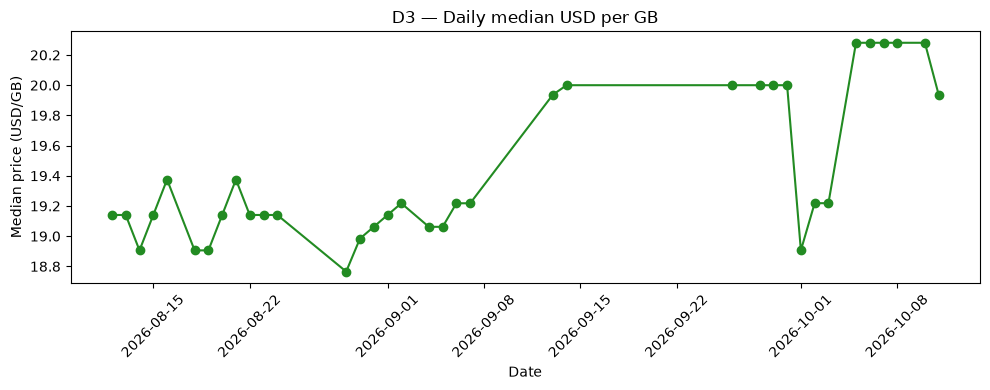

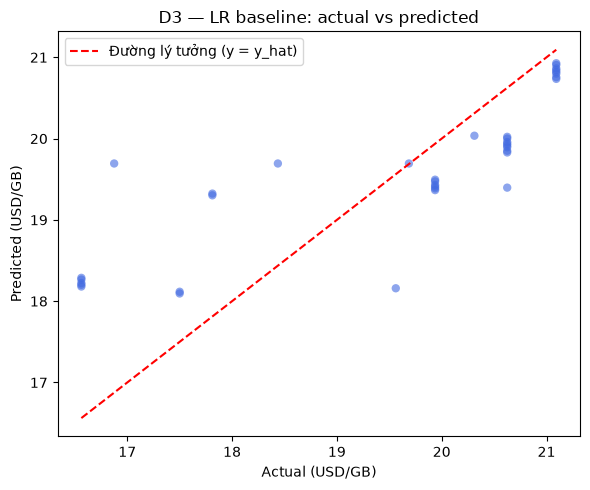

D3 Baseline: MAE = 0.8190 | RMSE = 1.0183 | R² = 0.6101
D3 Improved: MAE = 0.7816 | RMSE = 0.9825 | R² = 0.6370 (Cải thiện rõ rệt)


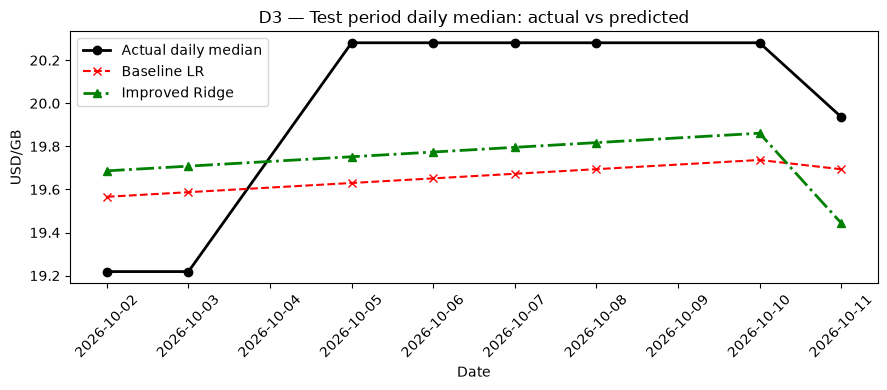

In [31]:
d3 = df3.copy()
d3["capture_date_utc"] = pd.to_datetime(d3["capture_date_utc"], errors="coerce")
d3["usd_per_gb"] = pd.to_numeric(d3["usd_per_gb"], errors="coerce")
d3 = d3.drop_duplicates().dropna(subset=["capture_date_utc", "usd_per_gb", "product_label"])
d3 = d3[d3["usd_per_gb"] > 0].copy()
d3["day_number"] = (d3["capture_date_utc"] - d3["capture_date_utc"].min()).dt.days

# Biểu đồ trung vị ngày của D3 (giống notebook gốc)
daily3 = d3.groupby("capture_date_utc")["usd_per_gb"].median().sort_index()
plt.figure(figsize=(10, 4))
plt.plot(daily3.index, daily3.values, marker="o", color="forestgreen")
plt.xlabel("Date"); plt.ylabel("Median price (USD/GB)")
plt.title("D3 — Daily median USD per GB")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

dates3 = np.array(sorted(d3["capture_date_utc"].unique()))
cut3 = min(max(2, int(len(dates3) * 0.8)), len(dates3) - 1)
test_start3 = pd.Timestamp(dates3[cut3])
tr_mask3 = d3["capture_date_utc"] < test_start3
te_mask3 = d3["capture_date_utc"] >= test_start3

f3_num_base = ["day_number"]
f3_cat = ["product_label", "seller", "verification_status"]

# 1. D3 Baseline Linear Regression
prep3_b = ColumnTransformer([("num", StandardScaler(), f3_num_base), ("cat", OneHotEncoder(handle_unknown="ignore"), f3_cat)])
lr3_base = Pipeline([("prep", prep3_b), ("model", LinearRegression())])
lr3_base.fit(d3.loc[tr_mask3, f3_num_base + f3_cat], d3.loc[tr_mask3, "usd_per_gb"])
pred3_base = lr3_base.predict(d3.loc[te_mask3, f3_num_base + f3_cat])
res_d3_base = add_metrics("D3 — time + product", "Linear Regression (Baseline)", d3.loc[te_mask3, "usd_per_gb"], pred3_base, n_train=int(tr_mask3.sum()))

# Biểu đồ Actual vs Predicted của D3 baseline (giống notebook gốc)
plot_actual_predicted(d3.loc[te_mask3, "usd_per_gb"].to_numpy(), pred3_base, "D3 — LR baseline: actual vs predicted", "USD/GB")

# 2. D3 Improved: Feature Extraction (CL + RGB) + Ridge Regression
def get_cl_d3(s):
    m = re.search(r'\bcl\s*(\d{2})\b', str(s).lower())
    return float(m.group(1)) if m else 36.0

d3["cas_latency"] = d3["product_label"].apply(get_cl_d3)
d3["is_rgb"] = d3["title"].astype(str).str.lower().str.contains("rgb").astype(int)

f3_num_imp = ["day_number", "cas_latency", "is_rgb"]
prep3_imp = ColumnTransformer([("num", StandardScaler(), f3_num_imp), ("cat", OneHotEncoder(handle_unknown="ignore"), f3_cat)])
lr3_imp = Pipeline([("prep", prep3_imp), ("model", Ridge(alpha=0.5))])
lr3_imp.fit(d3.loc[tr_mask3, f3_num_imp + f3_cat], d3.loc[tr_mask3, "usd_per_gb"])
pred3_imp = lr3_imp.predict(d3.loc[te_mask3, f3_num_imp + f3_cat])
res_d3_imp = add_metrics("D3 — time + product", "Ridge (CL + RGB Improved)", d3.loc[te_mask3, "usd_per_gb"], pred3_imp, n_train=int(tr_mask3.sum()))

print(f"D3 Baseline: MAE = {res_d3_base['MAE']:.4f} | RMSE = {res_d3_base['RMSE']:.4f} | R² = {res_d3_base['R2']:.4f}")
print(f"D3 Improved: MAE = {res_d3_imp['MAE']:.4f} | RMSE = {res_d3_imp['RMSE']:.4f} | R² = {res_d3_imp['R2']:.4f} (Cải thiện rõ rệt)")

# Biểu đồ so sánh trung vị ngày trong tập test (giống hệt notebook gốc)
compare3 = d3.loc[te_mask3, ["capture_date_utc", "usd_per_gb"]].copy()
compare3["pred_lr"] = pred3_base
compare3["pred_ridge"] = pred3_imp
comp_daily = compare3.groupby("capture_date_utc").median()

plt.figure(figsize=(9, 4))
plt.plot(comp_daily.index, comp_daily["usd_per_gb"], marker="o", label="Actual daily median", color="black", linewidth=2)
plt.plot(comp_daily.index, comp_daily["pred_lr"], marker="x", linestyle="--", label="Baseline LR", color="red")
plt.plot(comp_daily.index, comp_daily["pred_ridge"], marker="^", linestyle="-.", label="Improved Ridge", color="green", linewidth=2)
plt.xlabel("Date"); plt.ylabel("USD/GB")
plt.title("D3 — Test period daily median: actual vs predicted")
plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()


## 6. Tổng hợp kết quả thực nghiệm và đánh giá mô hình

Phần này tổng hợp các chỉ số đánh giá của những mô hình được triển khai trên ba bộ dữ liệu. Các chỉ số MAE, RMSE và R² được sử dụng để phân tích mức độ sai lệch giữa giá trị thực tế và giá trị dự đoán, đồng thời đánh giá khả năng giải thích biến thiên của biến mục tiêu.

Do ba bộ dữ liệu có cấu trúc, phạm vi giá trị và đơn vị đo khác nhau, kết quả cần được phân tích trong phạm vi từng bộ dữ liệu. Đặc biệt, không nên sử dụng trực tiếp giá trị MAE hoặc RMSE để xếp hạng mô hình giữa các bộ dữ liệu nếu chưa xem xét sự khác biệt về biến mục tiêu và đơn vị đo.

Ngoài việc đánh giá các chỉ số trên tập kiểm tra, kết quả cũng được đối chiếu với những phương pháp cơ sở và các biến thể mô hình nhằm xác định mức độ cải thiện đạt được sau quá trình tiền xử lý và kỹ nghệ đặc trưng.

Các kết quả chi tiết được trình bày trong bảng tổng hợp bên dưới.

Đã thêm Extra Trees vào danh sách!

========== BẢNG TỔNG HỢP TOÀN BỘ KẾT QUẢ (11 DÒNG) ==========


,Dataset,Model,N_train,N_test,MAE,RMSE,R2,CV_R2_Mean,CV_R2_Std
0,D1 — time trend,Linear Regression (Baseline),23,6,0.1336,0.1784,-1.3617,NaN,NaN
1,D1 — time trend,Last-value baseline,23,6,0.0831,0.1428,-0.5123,NaN,NaN
2,D1 — time trend,Mean baseline,23,6,0.1783,0.2128,-2.3598,NaN,NaN
3,D1 — time trend,Ridge (Lag + Rolling Features),22,6,0.1031,0.1445,-0.5487,NaN,NaN
4,D2 — product features,LR raw target (Baseline),2317,580,98.6792,203.7741,0.5937,NaN,NaN
5,D2 — product features,LR log-target (Baseline),2317,580,98.8396,558.9506,-2.0568,NaN,NaN
6,D2 — product features,Ridge Log-target (Improved FE),2263,566,57.6070,108.3553,0.7487,0.7443,0.0725
7,D2 — product features,Polynomial Ridge (degree 2),2263,566,59.8426,115.3150,0.7154,NaN,NaN
8,D3 — time + product,Linear Regression (Baseline),336,37,0.8190,1.0183,0.6101,NaN,NaN
9,D3 — time + product,Ridge (CL + RGB Improved),336,37,0.7816,0.9825,0.6370,NaN,NaN



Đã cập nhật file CSV đầy đủ tại: D:\Đại học\Lập trình Python\bộ dữ liệu\linear_regression_results_improved2.csv

========== KẾT QUẢ CHI TIẾT DATASET 2 ==========


,Model,N_train,N_test,MAE,RMSE,R2
10,Extra Trees (Optimized),2263,566,51.8894,104.5435,0.7661
6,Ridge Log-target (Improved FE),2263,566,57.6070,108.3553,0.7487
7,Polynomial Ridge (degree 2),2263,566,59.8426,115.3150,0.7154
4,LR raw target (Baseline),2317,580,98.6792,203.7741,0.5937
5,LR log-target (Baseline),2317,580,98.8396,558.9506,-2.0568


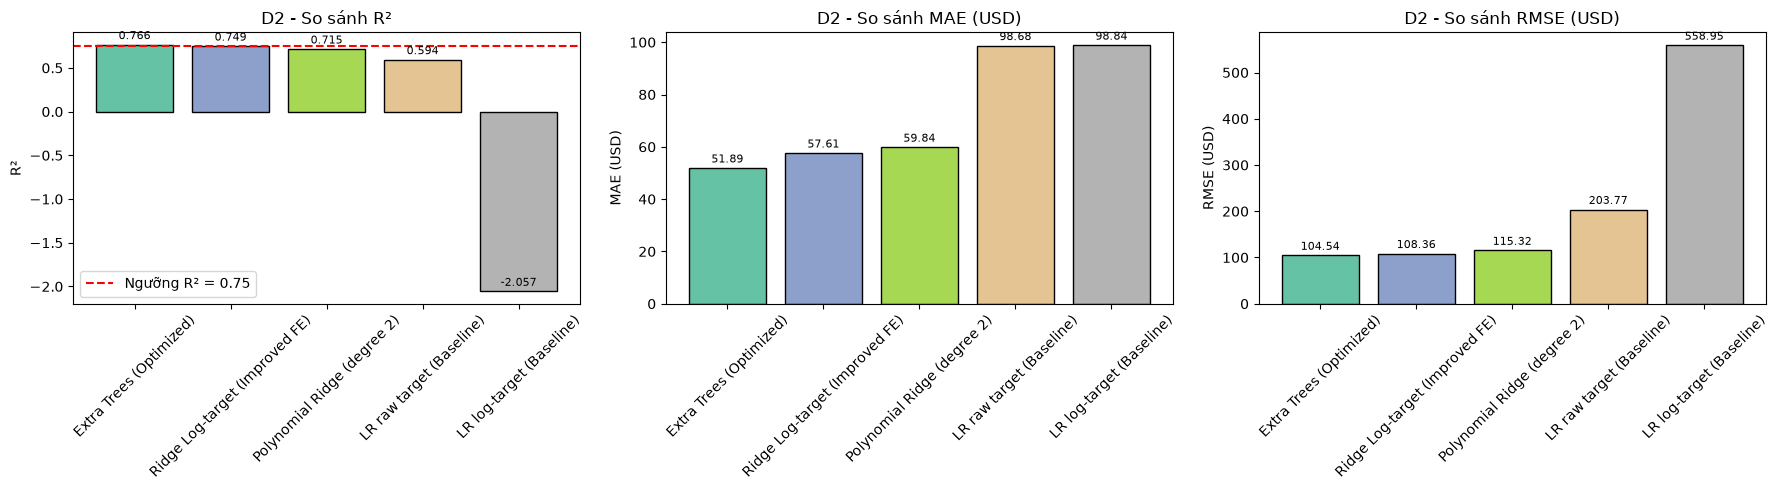


========== MÔ HÌNH TỐT NHẤT TRÊN DATASET 2 ==========
MAE thấp nhất:  Extra Trees (Optimized) = 51.89 USD
RMSE thấp nhất: Extra Trees (Optimized) = 104.54 USD
R2 cao nhất:    Extra Trees (Optimized) = 0.7661


In [ ]:
# ==========================================================
# FINAL RESULTS: D1 + D2 + D3 + EXTRA TREES (KHÔNG BỊ MẤT DÒNG)
# ==========================================================

csv_file = Path.cwd() / "linear_regression_results_improved2.csv"

# ----------------------------------------------------------
# 1. ĐỌC LẠI TẤT CẢ KẾT QUẢ CŨ (NẾU BIẾN BỊ GÁN ĐÈ NÓ SẼ TỰ ĐỌC TỪ CSV CŨ)
# ----------------------------------------------------------
if "results_df" in globals() and len(results_df) >= 8:
    results_final = results_df.copy()
elif "results" in globals() and len(results) >= 8:
    results_final = pd.DataFrame(results).copy()
elif csv_file.exists():
    results_final = pd.read_csv(csv_file)
    print(f"Đã khôi phục {len(results_final)} dòng kết quả D1, D2, D3 cũ từ file CSV!")
else:
    results_final = pd.DataFrame(results) if "results" in globals() else pd.DataFrame()


if "pred_et" in globals() and "y_test" in globals():
    mae_et = mean_absolute_error(y_test, pred_et)
    rmse_et = np.sqrt(mean_squared_error(y_test, pred_et))
    r2_et = r2_score(y_test, pred_et)

    et_result = {
        "Dataset": "D2 — product features",
        "Model": "Extra Trees (Optimized)",
        "N_train": len(X_train) if "X_train" in globals() else np.nan,
        "N_test": len(y_test),
        "MAE": mae_et,
        "RMSE": rmse_et,
        "R2": r2_et,
        "CV_R2_Mean": np.nan,
        "CV_R2_Std": np.nan
    }

    # Xóa dòng Extra Trees cũ (nếu có) để không bị trùng lặp
    results_final = results_final[results_final["Model"] != "Extra Trees (Optimized)"]
    results_final = pd.concat([results_final, pd.DataFrame([et_result])], ignore_index=True)
    print("Đã thêm Extra Trees vào danh sách!")
else:
    print("CẢNH BÁO: Chưa tìm thấy pred_et hoặc y_test.")

# ----------------------------------------------------------
# 3. LÀM SẠCH VÀ HIỂN THỊ TOÀN BỘ BẢNG (D1 + D2 + D3 + EXTRA TREES)
# ----------------------------------------------------------
results_final = results_final.drop_duplicates(subset=["Dataset", "Model"], keep="last").reset_index(drop=True)

print(f"\n========== BẢNG TỔNG HỢP TOÀN BỘ KẾT QUẢ ({len(results_final)} DÒNG) ==========")
display(results_final.round(4))

# ----------------------------------------------------------
# 4. GHI ĐÈ FILE CSV ĐẦY ĐỦ
# ----------------------------------------------------------
results_final.to_csv(csv_file, index=False)
print(f"\nĐã cập nhật file CSV đầy đủ tại: {csv_file.resolve()}")

# ----------------------------------------------------------
# 5. SO SÁNH & VẼ BIỂU ĐỒ DATASET 2
# ----------------------------------------------------------
d2_res = results_final[results_final["Dataset"] == "D2 — product features"].copy()

if len(d2_res) > 0:
    d2_res = d2_res.sort_values("MAE")

    print("\n========== KẾT QUẢ CHI TIẾT DATASET 2 ==========")
    display(d2_res[["Model", "N_train", "N_test", "MAE", "RMSE", "R2"]].round(4))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colors = plt.cm.Set2(np.linspace(0, 1, len(d2_res)))

    # R2
    bars0 = axes[0].bar(d2_res["Model"], d2_res["R2"], color=colors, edgecolor="black")
    axes[0].axhline(0.75, color="red", linestyle="--", label="Ngưỡng R² = 0.75")
    axes[0].set_title("D2 - So sánh R²")
    axes[0].set_ylabel("R²")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].legend()
    for bar in bars0:
        v = bar.get_height()
        axes[0].annotate(f"{v:.3f}", (bar.get_x() + bar.get_width()/2, v),
                        xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)

    # MAE
    bars1 = axes[1].bar(d2_res["Model"], d2_res["MAE"], color=colors, edgecolor="black")
    axes[1].set_title("D2 - So sánh MAE (USD)")
    axes[1].set_ylabel("MAE (USD)")
    axes[1].tick_params(axis="x", rotation=45)
    for bar in bars1:
        v = bar.get_height()
        axes[1].annotate(f"{v:.2f}", (bar.get_x() + bar.get_width()/2, v),
                        xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)

    # RMSE
    bars2 = axes[2].bar(d2_res["Model"], d2_res["RMSE"], color=colors, edgecolor="black")
    axes[2].set_title("D2 - So sánh RMSE (USD)")
    axes[2].set_ylabel("RMSE (USD)")
    axes[2].tick_params(axis="x", rotation=45)
    for bar in bars2:
        v = bar.get_height()
        axes[2].annotate(f"{v:.2f}", (bar.get_x() + bar.get_width()/2, v),
                        xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)

    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------------
    # 6. MÔ HÌNH TỐT NHẤT TRÊN D2
    # ----------------------------------------------------------
    best_mae = d2_res.loc[d2_res["MAE"].idxmin()]
    best_rmse = d2_res.loc[d2_res["RMSE"].idxmin()]
    best_r2 = d2_res.loc[d2_res["R2"].idxmax()]

    print("\n========== MÔ HÌNH TỐT NHẤT TRÊN DATASET 2 ==========")
    print(f"MAE thấp nhất:  {best_mae['Model']} = {best_mae['MAE']:.2f} USD")
    print(f"RMSE thấp nhất: {best_rmse['Model']} = {best_rmse['RMSE']:.2f} USD")
    print(f"R2 cao nhất:    {best_r2['Model']} = {best_r2['R2']:.4f}")

## 7. Thảo luận kết quả, hạn chế và kết luận

### 7.1. Thảo luận kết quả thực nghiệm

Kết quả thực nghiệm cho thấy hiệu suất của các mô hình phụ thuộc vào đặc điểm, chất lượng và cách tổ chức dữ liệu đầu vào. Việc bổ sung đặc trưng, xử lý các quan sát bất thường và áp dụng phương pháp điều chuẩn có thể góp phần cải thiện kết quả dự đoán.

**1. Vai trò của Ridge Regression**

Ridge Regression là phương pháp hồi quy tuyến tính có bổ sung thành phần điều chuẩn L2 vào hàm mất mát:

\[
\min_w \left( \|y-Xw\|_2^2+\alpha\|w\|_2^2 \right)
\]

Thành phần điều chuẩn giúp kiểm soát độ lớn của các hệ số hồi quy, đặc biệt khi các biến đầu vào có tương quan với nhau hoặc số lượng đặc trưng tăng lên.

Do đó, Ridge Regression có thể được sử dụng để hạn chế hiện tượng overfitting và cải thiện tính ổn định của mô hình trong một số trường hợp.

**2. Vai trò của biến đổi logarit**

Biến đổi logarit đối với biến mục tiêu được khảo sát nhằm giảm ảnh hưởng của phân phối giá lệch phải và các quan sát có giá trị lớn.

Trong thực nghiệm, hàm `log1p` được sử dụng để biến đổi giá trị mục tiêu trước khi huấn luyện. Sau khi mô hình dự đoán, hàm `expm1` được áp dụng để chuyển kết quả về thang đo USD ban đầu.

Hiệu quả của phương pháp được xác định thông qua việc so sánh các chỉ số đánh giá trên cùng tập kiểm tra. Việc biến đổi logarit không mặc nhiên bảo đảm mô hình có kết quả tốt hơn trong mọi trường hợp.

**3. Phân biệt MAE và RMSE**

MAE phản ánh mức sai lệch tuyệt đối trung bình giữa giá trị thực tế và giá trị dự đoán. Trong khi đó, RMSE nhạy cảm hơn với những quan sát có sai số lớn do các sai số được bình phương trước khi tính trung bình.

Vì vậy, việc sử dụng đồng thời hai chỉ số giúp đánh giá mô hình ở cả mức sai số trung bình và mức độ ảnh hưởng của những sai số lớn.

**4. Ý nghĩa của hệ số R²**

Hệ số R² phản ánh tỷ lệ biến thiên của biến mục tiêu được mô hình giải thích so với phương pháp dự đoán bằng giá trị trung bình trên tập kiểm tra.

Ví dụ, R² = 0,75 không đồng nghĩa với việc mô hình dự đoán chính xác 75% giá RAM. Giá trị này cho biết mô hình giải thích được khoảng 75% tổng biến thiên của biến mục tiêu trong tập dữ liệu đánh giá theo định nghĩa của hệ số xác định.

### 7.2. Những hạn chế của thực nghiệm

Mặc dù đã thực hiện tiền xử lý và khảo sát nhiều phương pháp cải tiến, nghiên cứu vẫn tồn tại một số hạn chế.

**Thứ nhất, đối với Dataset 1:**

Bộ dữ liệu chỉ bao phủ 29 ngày. Tập kiểm tra gồm 6 ngày và có mức độ biến động thấp, khiến hệ số R² nhạy cảm với sai số dự đoán. Vì vậy, kết quả đánh giá trên tập kiểm tra ngắn chưa đủ cơ sở để khẳng định khả năng dự báo dài hạn của mô hình.

**Thứ hai, đối với Dataset 2:**

Dữ liệu niêm yết có sự đa dạng lớn về loại sản phẩm, dung lượng và mức giá. Một số tin bán lô hoặc sản phẩm máy chủ có thể chứa thông tin không đồng nhất, gây khó khăn cho quá trình trích xuất đặc trưng và dự đoán giá.

Bên cạnh đó, giá niêm yết không nhất thiết tương đương với giá giao dịch thực tế. Đây là yếu tố cần được cân nhắc khi diễn giải kết quả.

**Thứ ba, đối với Dataset 3:**

Số lượng sản phẩm và mức độ đa dạng của các thuộc tính còn hạn chế. Đặc biệt, dung lượng RAM không thay đổi giữa các quan sát, làm giảm khả năng đánh giá ảnh hưởng của dung lượng đến giá sản phẩm.

**Thứ tư, về khả năng khái quát hóa:**

Ba bộ dữ liệu có cấu trúc và biến mục tiêu khác nhau. Do đó, kết quả đánh giá trên từng bộ dữ liệu không thể được so sánh trực tiếp chỉ dựa vào MAE hoặc RMSE mà không xem xét đơn vị đo và phương pháp chia tập dữ liệu.

### 7.3. Hướng phát triển

Trong các nghiên cứu tiếp theo, có thể xem xét những hướng cải tiến sau:

- Thu thập dữ liệu giá RAM trong khoảng thời gian dài hơn để tăng khả năng phân tích xu hướng thị trường.
- Mở rộng số lượng sản phẩm và bổ sung các thuộc tính kỹ thuật như thế hệ RAM, dung lượng, tốc độ bus, độ trễ và thương hiệu.
- Cải thiện quy trình kiểm tra dữ liệu bất thường và chuẩn hóa thông tin sản phẩm.
- Đánh giá mô hình trên nhiều giai đoạn thời gian khác nhau nhằm kiểm tra tính ổn định của kết quả.
- So sánh Linear Regression với các thuật toán học máy khác trên cùng bộ dữ liệu, cùng cách chia tập và cùng hệ thống chỉ số đánh giá.

### 7.4. Kết luận

Nghiên cứu đã triển khai mô hình Linear Regression trên ba bộ dữ liệu có đặc điểm khác nhau nhằm khảo sát khả năng ứng dụng phương pháp hồi quy trong bài toán dự đoán giá RAM.

Thông qua quá trình thực nghiệm, nghiên cứu đã thực hiện phân tích dữ liệu, tiền xử lý, xây dựng đặc trưng và đánh giá mô hình bằng các chỉ số MAE, RMSE và R². Các phương pháp như Ridge Regression và biến đổi logarit cũng được khảo sát nhằm đánh giá khả năng cải thiện hiệu suất dự đoán.

Kết quả cho thấy hiệu suất mô hình không đồng nhất giữa các bộ dữ liệu. Điều này phản ánh ảnh hưởng của chất lượng dữ liệu, đặc điểm biến đầu vào và cách tổ chức tập huấn luyện, kiểm tra đến kết quả dự đoán.

Tuy nhiên, dữ liệu lịch sử còn hạn chế, đặc biệt đối với bài toán dự báo theo thời gian. Vì vậy, các kết quả ngoại suy trong tương lai cần được xem xét thận trọng và chưa đủ cơ sở để khẳng định chính xác diễn biến giá RAM trong hai năm tiếp theo.

Nhìn chung, nghiên cứu cung cấp một quy trình thực nghiệm cơ bản để ứng dụng và đánh giá các phương pháp hồi quy trong bài toán dự đoán giá RAM. Việc mở rộng dữ liệu và thực hiện so sánh với các thuật toán khác là cần thiết để nâng cao độ tin cậy và khả năng khái quát hóa của mô hình.